# Maternal Risk Predictor — Data Preparation and EDA

**Target:** recorded birth before 37 completed weeks. Inspect → clean → select → engineer → split → preprocess.

Run this notebook first for the data workflow. Then open [02 — Models and Evaluation](02_models_and_evaluation.ipynb). Each notebook works from a fresh kernel. Detailed discussion is in [the report](../reports/REPORT.md).

## Setup — VS Code, Kaggle or Colab

Set paths and optional switches here; default review mode uses saved results.

In [1]:
from pathlib import Path
import os, sys, random, json, time, hashlib
SEED = 42
INPUT_ROOT_OVERRIDE = None  # e.g. '/kaggle/input/maternal-risk-project/project'
OUTPUT_ROOT_OVERRIDE = None # e.g. '/kaggle/working/maternal-risk-results'
RUN_TRAINING = False        # additional training/validation experiments only
RUN_DEEP_LEARNING = False  # requires RUN_TRAINING and TensorFlow
RUN_RAW_AUDIT = False      # streams the raw file; does not modify it
RUN_INGESTION = False      # streams selected fields into a NEW experiment parquet
MOUNT_GOOGLE_DRIVE = False # Colab only; leave off for local/Kaggle
RECALL_TARGETS = (0.70, 0.80) # illustrative validation targets, not clinical standards
TUNING_ROWS, SVM_ROWS, CV_FOLDS, N_JOBS = 60000, 6000, 3, 2

# Colab: optionally mount your Drive before resolving the project location.
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
candidates = [Path.cwd(), Path.cwd().parent]
if Path('/kaggle/input').exists():
    candidates += list(Path('/kaggle/input').glob('*')) + list(Path('/kaggle/input').glob('*/*'))
candidates += [Path('/content/drive/MyDrive/Maternal_Risk_Pridictor_Model')]
if INPUT_ROOT_OVERRIDE:
    INPUT_ROOT = Path(INPUT_ROOT_OVERRIDE).expanduser().resolve()
else:
    available = sorted({p.resolve() for p in candidates if (p/'data/processed/modeling_sample.parquet').exists()},key=str)
    if len(available)!=1:
        raise FileNotFoundError(f'Set INPUT_ROOT_OVERRIDE explicitly; compatible projects found: {available}')
    INPUT_ROOT = available[0]
HOSTED = Path('/kaggle').exists() or Path('/content').exists()
OUTPUT_ROOT = Path(OUTPUT_ROOT_OVERRIDE) if OUTPUT_ROOT_OVERRIDE else (
    Path('/kaggle/working/maternal-risk-results') if Path('/kaggle').exists() else
    Path('/content/maternal-risk-results') if Path('/content').exists() else INPUT_ROOT)
RAW = INPUT_ROOT/'Data/Nat2024PublicUS.c20250512.r20250708.txt'
GUIDE = INPUT_ROOT/'Data/UserGuide2024.pdf'
SAMPLE = INPUT_ROOT/'data/processed/modeling_sample.parquet'
STATE = INPUT_ROOT/'data/processed/state'
TABLES = INPUT_ROOT/'reports/tables'
EXPERIMENTS = OUTPUT_ROOT/'experiments/core'
RESULT_TABLES = OUTPUT_ROOT/'reports/tables/core'
FIGURES = OUTPUT_ROOT/'reports/figures/notebook'
for p in (EXPERIMENTS, FIGURES, RESULT_TABLES): p.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS','4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS','2')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','2')
sys.path.insert(0, str(INPUT_ROOT/'src'))  # compatibility for saved model objects
print({'input': str(INPUT_ROOT), 'outputs': str(OUTPUT_ROOT), 'training': RUN_TRAINING})

{'input': '/home/maurice/Documents/Intro_ML/Maternal_Risk_Pridictor_Model', 'outputs': '/home/maurice/Documents/Intro_ML/Maternal_Risk_Pridictor_Model', 'training': False}


### Optional dependencies

Use the pinned Python 3.13 environment locally; hosted installs are optional.

In [2]:
# VS Code terminal:
# python3.13 -m venv .venv
# .venv/bin/python -m pip install -r requirements.txt
# Kaggle/Colab: use the platform TensorFlow runtime. Only if packages are missing:
# %pip install "scikit-learn>=1.6,<2" pandas pyarrow matplotlib joblib
# %pip install tensorflow  # only if your hosted runtime does not already provide it

## Imports and reproducibility

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    RandomizedSearchCV, cross_validate, learning_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, fbeta_score, accuracy_score, brier_score_loss,
    balanced_accuracy_score, matthews_corrcoef, log_loss, confusion_matrix,
    classification_report, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (8,4), 'savefig.dpi':300,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__)
def show_table(filename):
    frame = pd.read_csv(TABLES/filename)
    display(frame)
    return frame

def save_figure(name):
    plt.tight_layout()
    destination=FIGURES/f'{name}.png'
    plt.savefig(destination, dpi=300, bbox_inches='tight')
    display(Image(filename=str(destination),width=1000))
    plt.close()

Python: 3.13.15 | pandas: 3.0.6


## Load the data dictionary and audit

Use the PDF-verified dictionary; preserve the raw file.

In [4]:
dictionary = pd.read_csv(TABLES/'stage1_data_dictionary.csv')
layout = pd.read_csv(TABLES/'stage1_corrected_variable_layout.csv')
audit = json.loads((TABLES/'stage1_audit_summary.json').read_text())
final_ingestion = json.loads((TABLES/'stage1_final_summary.json').read_text())
print('Saved streaming audit — raw rows:', f"{audit['raw_rows']:,}")
print('Record lengths:', audit['record_length_counts'])
print('Selected source columns:', len(dictionary))
print('User guide present:', GUIDE.exists())
display(dictionary[['field','description','start_1based','end_1based','role']].head())

Saved streaming audit — raw rows: 3,638,436
Record lengths: {'1345': 3638436}
Selected source columns: 118
User guide present: True


,field,description,start_1based,end_1based,role
0,F_BFACIL,Reporting Flag for Birth Place,33,33,REPORTING_FLAG
1,MAGER,Mother’s Single Years of Age,75,76,KEEP_candidate
2,F_MHISP,Reporting Flag for Mother’s Origin,116,116,REPORTING_FLAG
3,MRACEHISP,Mother’s Race/Hispanic Origin,117,117,KEEP_candidate
4,DMAR,Marital Status,120,120,KEEP_candidate


**Check:** Observed records have 15 trailing spaces beyond the guide; verified positions are unchanged.

## First look at the real dataset

Preview the saved cleaned sample first; the raw parsing and missing-code rules follow below. Explore training rows only.

In [5]:
data = pd.read_parquet(SAMPLE)
split_ids = np.load(STATE/'split_indices.npz')
train_ids, validation_ids, test_ids = [split_ids[k] for k in ('train','validation','test')]
joined = np.concatenate([train_ids, validation_ids, test_ids])
assert len(np.unique(joined)) == len(data) == len(joined)
assert joined.min() == 0 and joined.max() == len(data)-1
assert data.row_id.is_unique
train = data.iloc[train_ids].copy()
validation = data.iloc[validation_ids].copy()
# I retain test indices only; test features are not explored or predicted below.
print('Sample shape:', data.shape)
print({'training':len(train),'validation':len(validation),'test_locked':len(test_ids)})
# Match the rows behind the saved predictions, not merely the split sizes.
split_manifest=pd.read_csv(TABLES/'stage4_split_manifest.csv').set_index('split')
for label,ids in [('train',train_ids),('validation',validation_ids),('test_locked',test_ids)]:
    observed=hashlib.sha256(data.row_id.iloc[ids].to_numpy().tobytes()).hexdigest()
    assert observed==split_manifest.loc[label,'row_id_sha256'], 'Sample/split identity mismatch'


Sample shape: (300000, 120)
{'training': 210000, 'validation': 45000, 'test_locked': 45000}


## Make the column names meaningful

Readable names retain their original CDC mapping.

In [6]:
column_names = {'MAGER': 'maternal_age_years',
 'FAGECOMB': 'paternal_age_years',
 'PRIORLIVE': 'previous_births_now_living',
 'PRIORDEAD': 'previous_births_now_deceased',
 'PRIORTERM': 'previous_other_pregnancy_terminations',
 'CIG_0': 'daily_cigarettes_before_pregnancy',
 'M_Ht_In': 'maternal_height_inches',
 'BMI': 'prepregnancy_body_mass_index',
 'PWgt_R': 'prepregnancy_weight_pounds',
 'RF_CESARN': 'previous_cesarean_count',
 'MRACEHISP': 'maternal_race_ethnicity',
 'DMAR': 'maternal_marital_status',
 'MEDUC': 'maternal_education',
 'LBO_REC': 'live_birth_order_category',
 'TBO_REC': 'total_birth_order_category',
 'RF_PDIAB': 'prepregnancy_diabetes',
 'RF_PHYPE': 'prepregnancy_hypertension',
 'RF_PPTERM': 'previous_preterm_birth',
 'RF_INFTR': 'infertility_treatment',
 'RF_FEDRG': 'fertility_enhancing_drugs',
 'RF_ARTEC': 'assisted_reproductive_technology',
 'RF_CESAR': 'previous_cesarean',
 'DPLURAL': 'pregnancy_plurality',
 'advanced_age': 'maternal_age_at_least_35',
 'teen': 'maternal_age_under_20',
 'prior_preterm': 'previous_preterm_birth_indicator',
 'prior_pregnancy_none': 'no_previous_pregnancy_indicator',
 'risk_count': 'recorded_history_risk_count',
 'age_x_chronic_hypertension': 'advanced_age_with_chronic_hypertension',
 'plurality_x_prior_preterm': 'plurality_times_previous_preterm_indicator',
 'age_band': 'maternal_age_group',
 'bmi_category': 'prepregnancy_bmi_category',
 'PREVIS': 'total_prenatal_visits',
 'PREVIS_REC': 'prenatal_visit_count_category',
 'CIG_1': 'daily_cigarettes_first_trimester',
 'CIG_2': 'daily_cigarettes_second_trimester',
 'CIG_3': 'daily_cigarettes_third_trimester',
 'WTGAIN': 'pregnancy_weight_gain_pounds',
 'WTGAIN_REC': 'pregnancy_weight_gain_category',
 'RF_GDIAB': 'gestational_diabetes',
 'RF_GHYPE': 'gestational_hypertension',
 'RF_EHYPE': 'pregnancy_eclampsia',
 'WIC': 'wic_receipt_recorded',
 'IP_GON': 'gonorrhea_recorded',
 'IP_SYPH': 'syphilis_recorded',
 'IP_CHLAM': 'chlamydia_recorded',
 'IP_HEPB': 'hepatitis_b_recorded',
 'IP_HEPC': 'hepatitis_c_recorded',
 'OEGest_R3': 'obstetric_gestation_three_category',
 'GESTREC3': 'alternative_gestation_three_category',
 'OEGest_Comb': 'obstetric_gestation_weeks',
 'COMBGEST': 'alternative_gestation_weeks',
 'ILP_R': 'recorded_interval_since_previous_pregnancy',
 'PAY_REC': 'delivery_payment_category',
 'SEX': 'recorded_infant_sex',
 'target': 'preterm_birth',
 'row_id': 'source_record_id'}
readable_train = train.rename(columns=column_names)
display(pd.DataFrame({'CDC_code': list(column_names), 'meaningful_name':list(column_names.values())}))

,CDC_code,meaningful_name
0,MAGER,maternal_age_years
1,FAGECOMB,paternal_age_years
2,PRIORLIVE,previous_births_now_living
3,PRIORDEAD,previous_births_now_deceased
4,PRIORTERM,previous_other_pregnancy_terminations
5,CIG_0,daily_cigarettes_before_pregnancy
6,M_Ht_In,maternal_height_inches
7,BMI,prepregnancy_body_mass_index
8,PWgt_R,prepregnancy_weight_pounds
9,RF_CESARN,previous_cesarean_count


## Inspect the first five and last five training rows

Only training rows are previewed.

In [7]:
def preview_dataset(frame, rows=5):
    """Small real-data preview; pass training rows, never locked test rows."""
    print('Rows:',len(frame),'| Columns:',frame.shape[1])
    display(frame.head(rows))
    display(frame.tail(rows))
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str),
        'missing_pct':frame.isna().mean().mul(100)}))

preview_columns=['maternal_age_years','prepregnancy_body_mass_index',
    'previous_preterm_birth','pregnancy_plurality','preterm_birth']
preview_dataset(readable_train[preview_columns])

Rows: 210000 | Columns: 5


,maternal_age_years,prepregnancy_body_mass_index,previous_preterm_birth,pregnancy_plurality,preterm_birth
119417,28.0,18.7,N,1.0,0
236533,21.0,32.4,N,1.0,0
71405,28.0,29.1,N,1.0,0
219998,30.0,17.8,N,1.0,0
157382,26.0,27.1,N,1.0,0


,maternal_age_years,prepregnancy_body_mass_index,previous_preterm_birth,pregnancy_plurality,preterm_birth
139343,24.0,26.6,N,1.0,0
280484,42.0,26.1,N,1.0,0
155569,30.0,61.3,N,1.0,1
129217,35.0,26.3,N,1.0,0
206212,20.0,36.6,N,1.0,0


,dtype,missing_pct
maternal_age_years,float64,0.000000
prepregnancy_body_mass_index,float64,2.644286
previous_preterm_birth,string,0.389524
pregnancy_plurality,float64,0.000000
preterm_birth,int8,0.000000


## Optional streaming raw-row verification

Optional streaming verification; the full file is never loaded into memory.

In [8]:
if RUN_RAW_AUDIT:
    from collections import Counter
    lengths, endings, row_count = Counter(), Counter(), 0
    digest = hashlib.sha256()
    with RAW.open('rb') as stream:
        for line in stream:
            digest.update(line)
            record = line.rstrip(b'\r\n')
            lengths[len(record)] += 1
            endings['CRLF' if line.endswith(b'\r\n') else 'other'] += 1
            row_count += 1
            assert record[1330:].strip() == b'', 'Unexpected data beyond guide positions'
    print({'raw_rows':row_count, 'lengths':dict(lengths), 'endings':dict(endings),
           'sha256':digest.hexdigest()})
    assert row_count == audit['raw_rows'] and digest.hexdigest() == audit['sha256']
else:
    print('Using the saved completed streaming audit; enable RUN_RAW_AUDIT to repeat it.')

Using the saved completed streaming audit; enable RUN_RAW_AUDIT to repeat it.


## Select only the required raw fields

In [9]:
allowed_roles = {'KEEP_candidate','ABLATION_time_dependent','TARGET','REPORTING_FLAG'}
assert set(dictionary.role).issubset(allowed_roles)
colspecs = list(zip(dictionary.pandas_colspec_start.astype(int),
                   dictionary.pandas_colspec_end.astype(int)))
source_fields = dictionary.field.tolist()
assert len(source_fields) == len(set(source_fields))
print('Selected fixed-width fields:', len(source_fields))
print(source_fields)

Selected fixed-width fields: 118
['F_BFACIL', 'MAGER', 'F_MHISP', 'MRACEHISP', 'DMAR', 'F_MAR_P', 'MEDUC', 'F_MEDUC', 'FAGECOMB', 'F_FHISP', 'f_FEDUC', 'PRIORLIVE', 'PRIORDEAD', 'PRIORTERM', 'LBO_REC', 'TBO_REC', 'ILP_R', 'PRECARE', 'F_MPCB', 'PRECARE5', 'PREVIS', 'PREVIS_REC', 'F_TPCV', 'WIC', 'F_WIC', 'CIG_0', 'CIG_1', 'CIG_2', 'CIG_3', 'F_CIGS_0', 'F_CIGS_1', 'F_CIGS_2', 'F_CIGS_3', 'F_TOBACO', 'M_Ht_In', 'F_M_HT', 'BMI', 'BMI_R', 'PWgt_R', 'F_PWGT', 'F_DWGT', 'WTGAIN', 'WTGAIN_REC', 'F_WTGAIN', 'RF_PDIAB', 'RF_GDIAB', 'RF_PHYPE', 'RF_GHYPE', 'RF_EHYPE', 'RF_PPTERM', 'F_RF_PDIAB', 'F_RF_GDIAB', 'F_RF_PHYPER', 'F_RF_GHYPER', 'F_RF_ECLAMP', 'F_RF_PPB', 'RF_INFTR', 'RF_FEDRG', 'RF_ARTEC', 'f_RF_INFT', 'F_RF_INF_DRG', 'F_RF_INF_ART', 'RF_CESAR', 'RF_CESARN', 'F_RF_CESAR', 'F_RF_NCESAR', 'IP_GON', 'IP_SYPH', 'IP_CHLAM', 'IP_HEPB', 'IP_HEPC', 'F_IP_GONOR', 'F_IP_SYPH', 'F_IP_CHLAM', 'F_IP_HEPATB', 'F_IP_HEPATC', 'F_OB_SUCC', 'F_OB_FAIL', 'F_LD_INDL', 'F_LD_AUGM', 'F_LD_STER', 'F_LD_ANTB',

## Basic data exploration and handling missing values

Missing codes vary by field. Reporting flag zero overrides the recorded value.

In [10]:
missing_codes = {r.field: json.loads(r.missing_codes_json) for r in dictionary.itertuples()}
allowed_codes = {r.field: set(json.loads(r.allowed_nonblank_codes_json)) for r in dictionary.itertuples()}
display(dictionary[['field','kind','missing_codes_json','reporting_flag','semantic_note']])

,field,kind,missing_codes_json,reporting_flag,semantic_note
0,F_BFACIL,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."
1,MAGER,numeric,"[""""]",NaN,12 groups ages 10–12; 50 groups ages 50+. Age ...
2,F_MHISP,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."
3,MRACEHISP,numeric,"["""", ""8""]",NaN,Protected/social grouping; suitability for pre...
4,DMAR,numeric,"[""""]",NaN,US codes only. Puerto Rico 3/9 are not accepte...
...,...,...,...,...,...
113,F_CA_CLEFT,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."
114,F_CA_DOWNS,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."
115,F_CA_CHROM,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."
116,F_CA_HYPOS,numeric,"[""""]",NaN,"0 non-reporting; 1 reporting. Audit only, neve..."


### Apply cleaning rules

In [11]:
def clean_raw_chunk(raw_chunk):
    cleaned = {}
    for entry in dictionary.itertuples():
        values = raw_chunk[entry.field].fillna('').astype(str).str.strip()
        unexpected = set(values.unique()) - allowed_codes[entry.field] - {''}
        if unexpected:
            raise ValueError(f'Misaligned or unexpected {entry.field}: {unexpected}')
        values = values.mask(values.isin(missing_codes[entry.field]))
        if entry.kind == 'numeric':
            cleaned[entry.field] = pd.to_numeric(values, errors='raise').astype(float)
        else:
            cleaned[entry.field] = values.astype('string')
    cleaned = pd.DataFrame(cleaned,index=raw_chunk.index)
    for entry in dictionary.itertuples():
        if pd.notna(entry.reporting_flag):
            flag = entry.reporting_flag
            cleaned.loc[cleaned[flag].eq(0), entry.field] = np.nan
    return cleaned

# Optional regeneration writes to experiments/, never over the audited source/cache.
if RUN_INGESTION:
    import pyarrow as pa
    import pyarrow.parquet as pq
    destination = EXPERIMENTS/'selected_fields_reingested.parquet'
    if destination.exists(): raise FileExistsError(destination)
    writer = None
    total, missing_counts = 0, pd.Series(0, index=source_fields, dtype='int64')
    try:
        reader = pd.read_fwf(RAW, colspecs=colspecs, names=source_fields,
                             dtype=str, keep_default_na=False, chunksize=100000)
        for raw_chunk in reader:
            clean_chunk = clean_raw_chunk(raw_chunk)
            missing_counts += clean_chunk.isna().sum()
            table = pa.Table.from_pandas(clean_chunk, preserve_index=False)
            if writer is None: writer = pq.ParquetWriter(destination, table.schema)
            writer.write_table(table)
            total += len(clean_chunk)
    finally:
        if writer is not None: writer.close()
    assert total == audit['raw_rows']
    display((missing_counts/total*100).rename('missing_pct').to_frame())
else:
    print('Completed ingestion evidence follows; full raw re-ingestion is disabled.')

Completed ingestion evidence follows; full raw re-ingestion is disabled.


**Check:** ILP_R=888 is a real category; zeroes and fertility X are not universal missing codes.

## Missing-value counts after cleaning

Full-cohort missingness is measured before training-only imputation.

In [12]:
missingness = pd.read_csv(TABLES/'stage1_missingness_final.csv')
display(missingness.sort_values('missing_pct', ascending=False))
print('Additional missing cells from non-reporting flags:',
      f"{final_ingestion['additional_missing_cells']:,}")

,field,role,raw_rows,missing_count,missing_pct
4,DMAR,KEEP_candidate,3638436,402966,11.075253
16,ILP_R,KEEP_candidate,3638436,394332,10.837953
8,FAGECOMB,KEEP_candidate,3638436,363459,9.989430
57,RF_FEDRG,KEEP_candidate,3638436,267569,7.353956
58,RF_ARTEC,KEEP_candidate,3638436,267569,7.353956
...,...,...,...,...,...
113,F_CA_CLEFT,REPORTING_FLAG,3638436,0,0.000000
114,F_CA_DOWNS,REPORTING_FLAG,3638436,0,0.000000
115,F_CA_CHROM,REPORTING_FLAG,3638436,0,0.000000
116,F_CA_HYPOS,REPORTING_FLAG,3638436,0,0.000000


Additional missing cells from non-reporting flags: 1,055,719


## Check cleaning directly against raw codes

Compare selected training records against their original fixed-width codes.

In [13]:
if RAW.exists():
    record_length = int(next(iter(audit['record_length_counts'])))
    assert list(audit['line_endings']) == ['CRLF']
    records = []
    with RAW.open('rb') as stream:
        for source_id in train.row_id.head(5).astype(int):
            stream.seek(source_id*(record_length+2))
            line = stream.readline().rstrip(b'\r\n').decode('ascii')
            assert len(line) == record_length
            records.append({f:line[a:b].strip() for f,(a,b) in zip(source_fields,colspecs)})
    raw_preview = pd.DataFrame(records)
    cleaned_preview = clean_raw_chunk(raw_preview)
    inspect_fields = ['MAGER','BMI','ILP_R','RF_PPTERM','RF_FEDRG','OEGest_R3']
    display(raw_preview[inspect_fields].add_prefix('raw__'))
    display(cleaned_preview[inspect_fields].rename(columns=column_names).add_prefix('clean__'))
    for f in source_fields:
        actual = train[f].head(5).reset_index(drop=True)
        expected = cleaned_preview[f].reset_index(drop=True)
        assert actual.fillna('__MISSING__').astype(str).equals(expected.fillna('__MISSING__').astype(str)), f
    print('All selected fields in these training examples agree with the cleaned parquet.')
else:
    print('Raw file omitted in hosted review mode; use dictionary and saved audit evidence.')

,raw__MAGER,raw__BMI,raw__ILP_R,raw__RF_PPTERM,raw__RF_FEDRG,raw__OEGest_R3
0,28,18.7,074,N,X,2
1,21,32.4,032,N,X,2
2,28,29.1,888,N,X,2
3,30,17.8,026,N,X,2
4,26,27.1,058,N,X,2


,clean__maternal_age_years,clean__prepregnancy_body_mass_index,clean__recorded_interval_since_previous_pregnancy,clean__previous_preterm_birth,clean__fertility_enhancing_drugs,clean__obstetric_gestation_three_category
0,28.0,18.7,74.0,N,X,2.0
1,21.0,32.4,32.0,N,X,2.0
2,28.0,29.1,888.0,N,X,2.0
3,30.0,17.8,26.0,N,X,2.0
4,26.0,27.1,58.0,N,<NA>,2.0


All selected fields in these training examples agree with the cleaned parquet.


## Define the binary target and remove unknown outcomes

OEGest_R3: 1 → preterm, 2 → term; unknown code 3 is excluded.

In [14]:
assert data.OEGest_R3.isin([1,2]).all()
assert np.array_equal(data.target.to_numpy(), data.OEGest_R3.eq(1).astype('int8').to_numpy())
balance = pd.read_csv(TABLES/'stage2_class_balance.csv')
sampling_details = json.loads((TABLES/'stage2_sampling.json').read_text())
display(balance)
display(pd.Series(sampling_details, name='documented_sampling'))
print('Target code: OEGest_R3 == 1 → positive; OEGest_R3 == 2 → negative.')

,population,rows,preterm,term,preterm_ratio
0,full_known_target,3633827,377948,3255879,0.104008
1,stratified_sample,300000,31202,268798,0.104007


raw_rows                                                               3638436
target_code3_dropped                                                      4609
known_target_rows                                                      3633827
sample_rows                                                             300000
seed                                                                        42
sampling                     Exact per-class random-priority reservoir, uni...
ratio_absolute_difference                                             0.000002
justification                300k bounds local tuning/embedding memory whil...
Name: documented_sampling, dtype: object

Target code: OEGest_R3 == 1 → positive; OEGest_R3 == 2 → negative.


**Result:** Stratification preserves the observed minority class; this remains a retrospective birth-cohort study.

## Optional reproducible stratified sampling from the parsed cache

Optional new sampling study; never overwrite the established sample or split.

In [15]:
def stratified_sample_parquet(cache_path, positive_n, negative_n, seed=SEED):
    import pyarrow.parquet as pq
    rng = np.random.default_rng(seed)
    # First pass: exact known-outcome counts, without loading all rows.
    counts = {1:0, 2:0}
    for batch in pq.ParquetFile(cache_path).iter_batches(batch_size=100000, columns=['OEGest_R3']):
        s = batch.to_pandas()['OEGest_R3']
        for label in counts: counts[label] += int(s.eq(label).sum())
    remaining, needed = counts.copy(), {1:int(positive_n), 2:int(negative_n)}
    assert all(0 <= needed[k] <= counts[k] for k in counts)
    pieces, offset = [], 0
    for batch in pq.ParquetFile(cache_path).iter_batches(batch_size=100000):
        chunk = batch.to_pandas()
        chunk['row_id'] = np.arange(offset, offset+len(chunk))
        offset += len(chunk)
        for label in counts:
            group = chunk.loc[chunk.OEGest_R3.eq(label)]
            n = len(group)
            take = int(rng.hypergeometric(n, remaining[label]-n, needed[label])) if needed[label] else 0
            if take: pieces.append(group.iloc[rng.choice(n,take,replace=False)])
            needed[label] -= take
            remaining[label] -= n
    assert not any(needed.values())
    result = pd.concat(pieces).sort_values('row_id').reset_index(drop=True)
    result['target'] = result.OEGest_R3.eq(1).astype('int8')
    return result

# Example for a separate study, after selecting a new sample size in advance:
# new_sample = stratified_sample_parquet(INPUT_ROOT/'data/processed/natality2024_selected_full.parquet',
#                                       positive_n=31202, negative_n=268798)
# new_sample.to_parquet(EXPERIMENTS/'new_modeling_sample.parquet', index=False)

## Inspect types, missingness and summary statistics

In [16]:
readable_train.info()
display(readable_train.describe(include='all').T)
display(readable_train.isna().mean().mul(100).sort_values(ascending=False).rename('training_missing_pct').to_frame())

<class 'pandas.DataFrame'>
Index: 210000 entries, 119417 to 206212
Columns: 120 entries, F_BFACIL to preterm_birth
dtypes: float64(101), int64(1), int8(1), string(17)
memory usage: 196.2 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
F_BFACIL,210000.0,NaN,NaN,NaN,0.997433,0.050597,0.0,1.0,1.0,1.0,1.0
maternal_age_years,210000.0,NaN,NaN,NaN,29.660062,5.817052,12.0,25.0,30.0,34.0,50.0
F_MHISP,210000.0,NaN,NaN,NaN,0.997433,0.050597,0.0,1.0,1.0,1.0,1.0
maternal_race_ethnicity,208092.0,NaN,NaN,NaN,3.122686,2.608697,1.0,1.0,2.0,7.0,7.0
maternal_marital_status,186781.0,NaN,NaN,NaN,1.397578,0.489399,1.0,1.0,1.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...
F_CA_CHROM,210000.0,NaN,NaN,NaN,0.997433,0.050597,0.0,1.0,1.0,1.0,1.0
F_CA_HYPOS,210000.0,NaN,NaN,NaN,0.997433,0.050597,0.0,1.0,1.0,1.0,1.0
F_BFED,210000.0,NaN,NaN,NaN,0.887071,0.316506,0.0,1.0,1.0,1.0,1.0
source_record_id,210000.0,NaN,NaN,NaN,1821316.423943,1050780.169855,17.0,910726.5,1823638.5,2732378.25,3638421.0


,training_missing_pct
maternal_marital_status,11.056667
recorded_interval_since_previous_pregnancy,10.742857
paternal_age_years,9.969524
fertility_enhancing_drugs,7.224762
assisted_reproductive_technology,7.224762
...,...
F_CA_CHROM,0.000000
F_CA_HYPOS,0.000000
F_BFED,0.000000
source_record_id,0.000000


## Features and target — reduce before modeling

Keep prenatal inputs; later-pregnancy and outcome fields remain outside the core.

In [17]:
core_numeric_codes = ['MAGER','FAGECOMB','PRIORLIVE','PRIORDEAD','PRIORTERM','CIG_0',
                      'M_Ht_In','BMI','PWgt_R','RF_CESARN']
core_categorical_codes = ['MRACEHISP','DMAR','MEDUC','LBO_REC','TBO_REC','RF_PDIAB',
    'RF_PHYPE','RF_PPTERM','RF_INFTR','RF_FEDRG','RF_ARTEC','RF_CESAR','DPLURAL']
core_numeric = [column_names[f] for f in core_numeric_codes]
core_categorical = [column_names[f] for f in core_categorical_codes]
core_fields = core_numeric_codes + core_categorical_codes
assert not any(layout.set_index('field').loc[f,'role']=='EXCLUDE_leakage' for f in core_fields)
feature_catalog = pd.read_csv(TABLES/'stage3_leakage_audit.csv')
display(feature_catalog)
print('Core source predictors:', len(core_fields))
print('Additional auxiliary input: ILP_R, only to derive the no-previous-pregnancy indicator.')
display(pd.DataFrame({'stage':['Audited source columns','Core source predictors','Engineered inputs','Total model inputs'],
    'columns':[len(dictionary),len(core_fields),9,len(core_fields)+9]}))

,field,input_role,decision,reason
0,DOB_YY,EXCLUDE_leakage,EXCLUDE,birth date outcome-dependent
1,DOB_MM,EXCLUDE_leakage,EXCLUDE,birth month shifts with gestation
2,DOB_TT,EXCLUDE_leakage,EXCLUDE,delivery time
3,DOB_WK,EXCLUDE_leakage,EXCLUDE,delivery weekday
4,BFACIL,EXCLUDE_leakage,EXCLUDE,place of delivery
...,...,...,...,...
214,NO_CONGEN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
215,ITRAN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
216,ILIVE,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
217,BFED,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...


Core source predictors: 23
Additional auxiliary input: ILP_R, only to derive the no-previous-pregnancy indicator.


,stage,columns
0,Audited source columns,118
1,Core source predictors,23
2,Engineered inputs,9
3,Total model inputs,32


**Check:** PRIORTERM means pregnancy terminations. Numeric birth-derived intervals and outcome proxies are excluded.

## Encode binary fields without losing unknown values

Map Y/N to 1/0; unknown stays missing and fertility X stays a category.

In [18]:
yes_no_codes = ['RF_PDIAB','RF_PHYPE','RF_PPTERM','RF_INFTR','RF_CESAR']
display(pd.DataFrame({column_names[f]: train[f].value_counts(dropna=False) for f in yes_no_codes}).fillna(0))
yes_no_map = {'Y':1.0,'N':0.0}
binary_training = pd.DataFrame({column_names[f]:train[f].map(yes_no_map) for f in yes_no_codes})
display(binary_training.head())
print('Fertility-drug categories:', train.RF_FEDRG.value_counts(dropna=False).to_dict())

,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,previous_cesarean
N,206411,202233,200791,189783,176728
Y,2771,6949,8391,5178,32454
<NA>,818,818,818,15039,818


,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,previous_cesarean
119417,0.0,0.0,0.0,0.0,0.0
236533,0.0,0.0,0.0,0.0,1.0
71405,0.0,0.0,0.0,0.0,0.0
219998,0.0,0.0,0.0,0.0,1.0
157382,0.0,0.0,0.0,NaN,0.0


Fertility-drug categories: {'X': 189783, <NA>: 15172, 'N': 3472, 'Y': 1573}


## Encode ordinal and nominal categories appropriately

Category numbers are labels; train-fitted encoders handle unseen values.

In [19]:
from readable_features import code_legend
category_legend = code_legend()
display(category_legend)
# Example mapping for interpretation only; modeling retains stable category codes.
education_labels = category_legend.loc[category_legend.source_code.eq('MEDUC')]
display(education_labels)

,source_code,readable_name,code,meaning
0,MRACEHISP,maternal_race_ethnicity,1,Non-Hispanic White
1,MRACEHISP,maternal_race_ethnicity,2,Non-Hispanic Black
2,MRACEHISP,maternal_race_ethnicity,3,Non-Hispanic American Indian/Alaska Native
3,MRACEHISP,maternal_race_ethnicity,4,Non-Hispanic Asian
4,MRACEHISP,maternal_race_ethnicity,5,Non-Hispanic Native Hawaiian/Other Pacific Isl...
5,MRACEHISP,maternal_race_ethnicity,6,Non-Hispanic more than one race
6,MRACEHISP,maternal_race_ethnicity,7,Hispanic
7,MRACEHISP,maternal_race_ethnicity,8,Unknown/not stated
8,DMAR,maternal_marital_status,1,Married
9,DMAR,maternal_marital_status,2,Unmarried


,source_code,readable_name,code,meaning
10,MEDUC,maternal_education,1,8th grade or less
11,MEDUC,maternal_education,2,"9th-12th grade, no diploma"
12,MEDUC,maternal_education,3,High school/GED
13,MEDUC,maternal_education,4,"Some college, no degree"
14,MEDUC,maternal_education,5,Associate degree
15,MEDUC,maternal_education,6,Bachelor degree
16,MEDUC,maternal_education,7,Master degree
17,MEDUC,maternal_education,8,Doctorate/professional degree
18,MEDUC,maternal_education,9,Unknown


## Check outliers and original measurement units

Inspect training quantiles; do not cap valid extremes using the full sample.

,0.00,0.01,0.05,0.50,0.95,0.99,1.00
maternal_age_years,12.0,18.0,20.0,30.0,39.0,42.00,50.0
prepregnancy_body_mass_index,13.0,17.4,19.3,26.6,41.2,49.10,69.5
prepregnancy_weight_pounds,75.0,98.0,110.0,155.0,245.0,296.00,375.0
daily_cigarettes_before_pregnancy,0.0,0.0,0.0,0.0,0.0,18.38,98.0


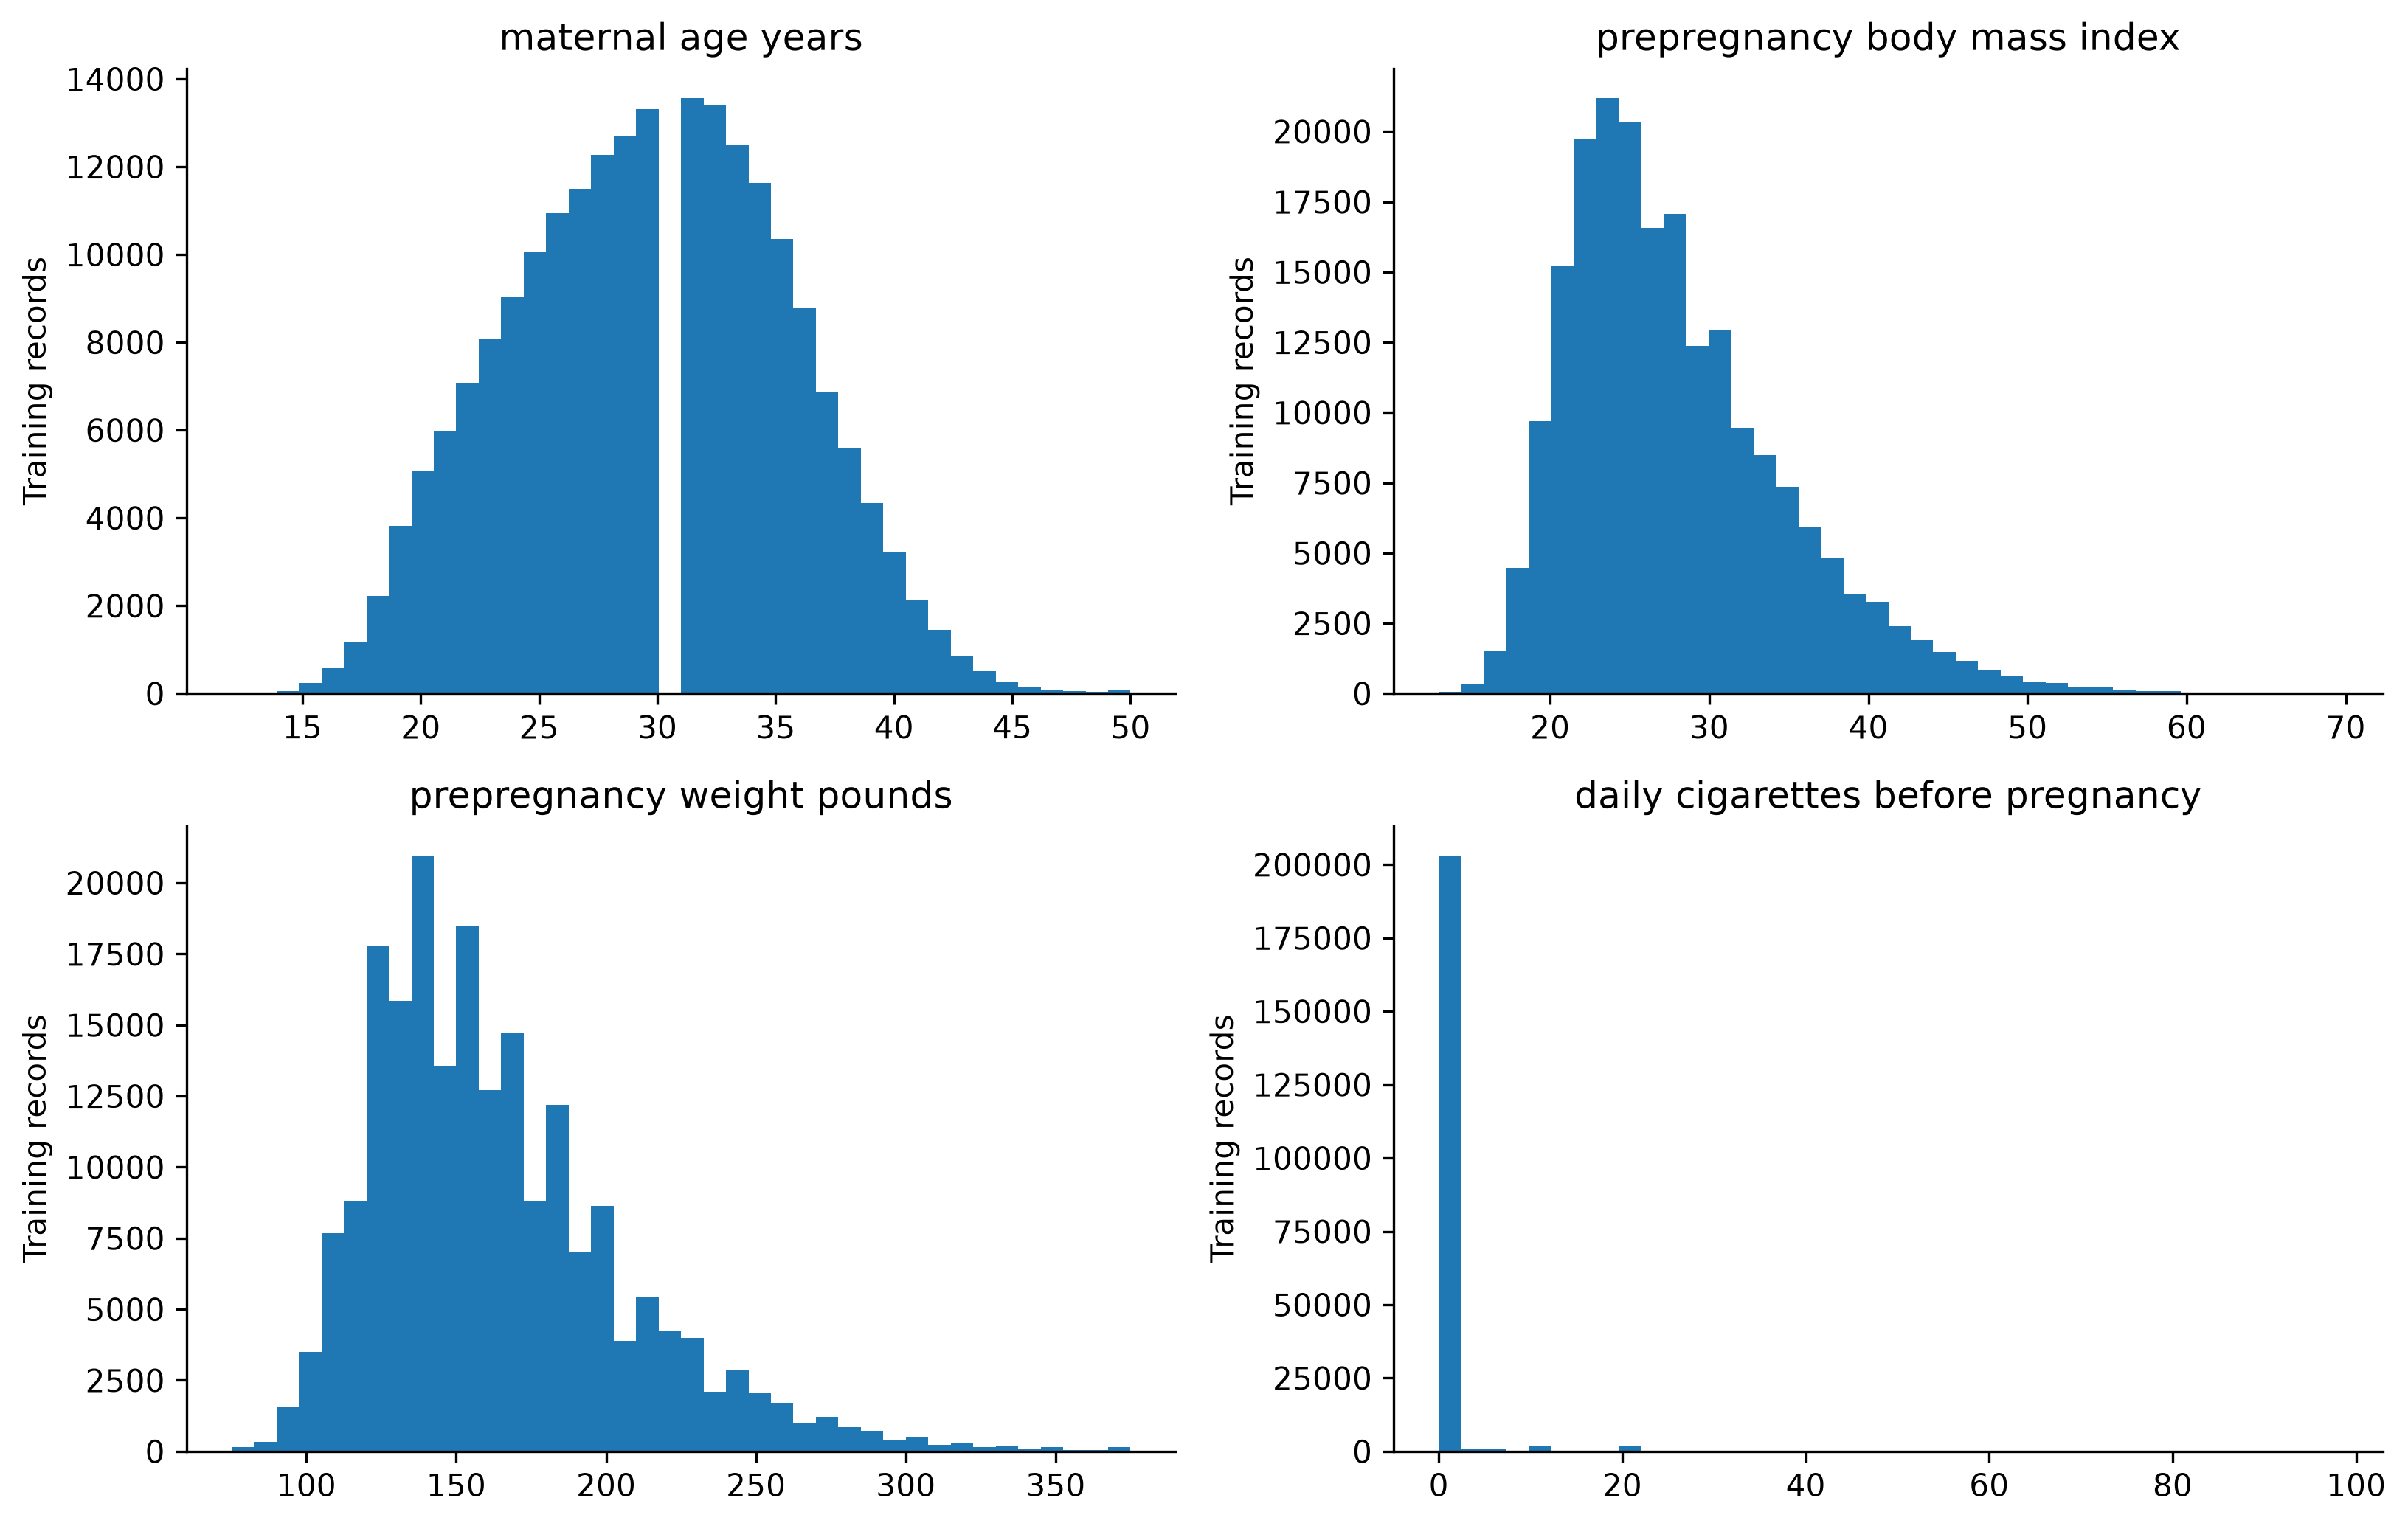

In [20]:
quantile_fields = ['maternal_age_years','prepregnancy_body_mass_index',
                   'prepregnancy_weight_pounds','daily_cigarettes_before_pregnancy']
display(readable_train[quantile_fields].quantile([0,.01,.05,.5,.95,.99,1]).T)
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax, field in zip(axes.flat,quantile_fields):
    ax.hist(readable_train[field].dropna(),bins=40)
    ax.set_title(field.replace('_',' ')); ax.set_ylabel('Training records')
save_figure('training_numeric_distributions')

**Decision:** Retain plausible extremes; any learned clipping must stay inside training folds.

## Feature engineering

Fixed transformations only; preserve missingness in composite risk features.

In [21]:
def engineer_features(frame, engineered=True, time_dependent=False):
    x = frame.rename(columns=column_names).copy()
    numeric, categorical = core_numeric.copy(), core_categorical.copy()
    if engineered:
        age, bmi = x.maternal_age_years, x.prepregnancy_body_mass_index
        x['maternal_age_at_least_35'] = age.ge(35).astype(float).mask(age.isna())
        x['maternal_age_under_20'] = age.lt(20).astype(float).mask(age.isna())
        x['previous_preterm_birth_indicator'] = x.previous_preterm_birth.map(yes_no_map)
        interval = x.recorded_interval_since_previous_pregnancy
        x['no_previous_pregnancy_indicator'] = interval.eq(888).astype(float).mask(interval.isna())
        risk_fields = [column_names[f] for f in yes_no_codes]
        risks = pd.DataFrame({f:x[f].map(yes_no_map) for f in risk_fields})
        x['recorded_history_risk_count'] = risks.sum(axis=1,min_count=len(risk_fields))
        x['advanced_age_with_chronic_hypertension'] = x.maternal_age_at_least_35*x.prepregnancy_hypertension.map(yes_no_map)
        x['plurality_times_previous_preterm_indicator'] = x.pregnancy_plurality*x.previous_preterm_birth_indicator
        x['maternal_age_group'] = pd.cut(age,[-np.inf,19,24,29,34,39,np.inf],
            labels=['<20','20–24','25–29','30–34','35–39','40+']).astype('string')
        x['prepregnancy_bmi_category'] = pd.cut(bmi,[-np.inf,18.5,25,30,35,40,np.inf],right=False,
            labels=['underweight','normal','overweight','obesity_I','obesity_II','obesity_III']).astype('string')
        numeric += ['maternal_age_at_least_35','maternal_age_under_20','previous_preterm_birth_indicator',
            'no_previous_pregnancy_indicator','recorded_history_risk_count',
            'advanced_age_with_chronic_hypertension','plurality_times_previous_preterm_indicator']
        categorical += ['maternal_age_group','prepregnancy_bmi_category']
    if time_dependent:
        numeric += [column_names[f] for f in ['PREVIS','CIG_1','CIG_2','CIG_3','WTGAIN']]
        categorical += [column_names[f] for f in ['PREVIS_REC','WTGAIN_REC','RF_GDIAB','RF_GHYPE',
            'RF_EHYPE','WIC','IP_GON','IP_SYPH','IP_CHLAM','IP_HEPB','IP_HEPC']]
    x = x[numeric+categorical].copy()
    for f in numeric: x[f] = pd.to_numeric(x[f],errors='raise').astype(float)
    for f in categorical: x[f] = x[f].astype('string').fillna('__MISSING__').astype(object)
    return x, numeric, categorical

X_train, numeric_features, categorical_features = engineer_features(train)
X_validation, _, _ = engineer_features(validation)
y_train, y_validation = train.target.astype(int), validation.target.astype(int)
assert 'preterm_birth' not in X_train and 'obstetric_gestation_three_category' not in X_train
print({'source_predictors':len(core_fields),'engineered_predictors':9,
       'final_model_inputs':X_train.shape[1], 'numeric':len(numeric_features),
       'categorical':len(categorical_features)})
display(X_train.head(5)); display(X_train.tail(5))

{'source_predictors': 23, 'engineered_predictors': 9, 'final_model_inputs': 32, 'numeric': 17, 'categorical': 15}


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,maternal_age_at_least_35,maternal_age_under_20,previous_preterm_birth_indicator,no_previous_pregnancy_indicator,recorded_history_risk_count,advanced_age_with_chronic_hypertension,plurality_times_previous_preterm_indicator,maternal_race_ethnicity,maternal_marital_status,maternal_education,live_birth_order_category,total_birth_order_category,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
119417,28.0,31.0,2.0,0.0,0.0,0.0,66.0,18.7,116.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,3.0,3.0,N,N,N,N,X,X,N,1.0,25–29,normal
236533,21.0,NaN,1.0,0.0,0.0,0.0,63.0,32.4,183.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.0,2.0,3.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,20–24,obesity_I
71405,28.0,35.0,0.0,0.0,0.0,0.0,65.0,29.1,175.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,7.0,1.0,3.0,1.0,1.0,N,N,N,N,X,X,N,1.0,25–29,overweight
219998,30.0,27.0,1.0,0.0,0.0,0.0,66.0,17.8,110.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,3.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,30–34,underweight
157382,26.0,34.0,2.0,0.0,0.0,0.0,67.0,27.1,173.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,1.0,1.0,4.0,3.0,3.0,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,25–29,overweight


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,maternal_age_at_least_35,maternal_age_under_20,previous_preterm_birth_indicator,no_previous_pregnancy_indicator,recorded_history_risk_count,advanced_age_with_chronic_hypertension,plurality_times_previous_preterm_indicator,maternal_race_ethnicity,maternal_marital_status,maternal_education,live_birth_order_category,total_birth_order_category,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
139343,24.0,33.0,2.0,0.0,0.0,0.0,63.0,26.6,150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,3.0,3.0,N,N,N,N,X,X,N,1.0,20–24,overweight
280484,42.0,41.0,1.0,0.0,0.0,0.0,61.0,26.1,138.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,1.0,8.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,40+,overweight
155569,30.0,NaN,3.0,0.0,0.0,0.0,64.0,61.3,357.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,2.0,2.0,3.0,4.0,4.0,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,30–34,obesity_III
129217,35.0,34.0,3.0,0.0,0.0,0.0,68.0,26.3,173.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8.0,4.0,4.0,N,N,N,N,X,X,N,1.0,35–39,overweight
206212,20.0,22.0,0.0,NaN,0.0,0.0,62.0,36.6,200.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7.0,1.0,3.0,__MISSING__,__MISSING__,N,N,N,N,X,X,N,1.0,20–24,obesity_II


## Class imbalance

,rows,fraction
preterm_birth,,
0,188158,0.89599
1,21842,0.10401


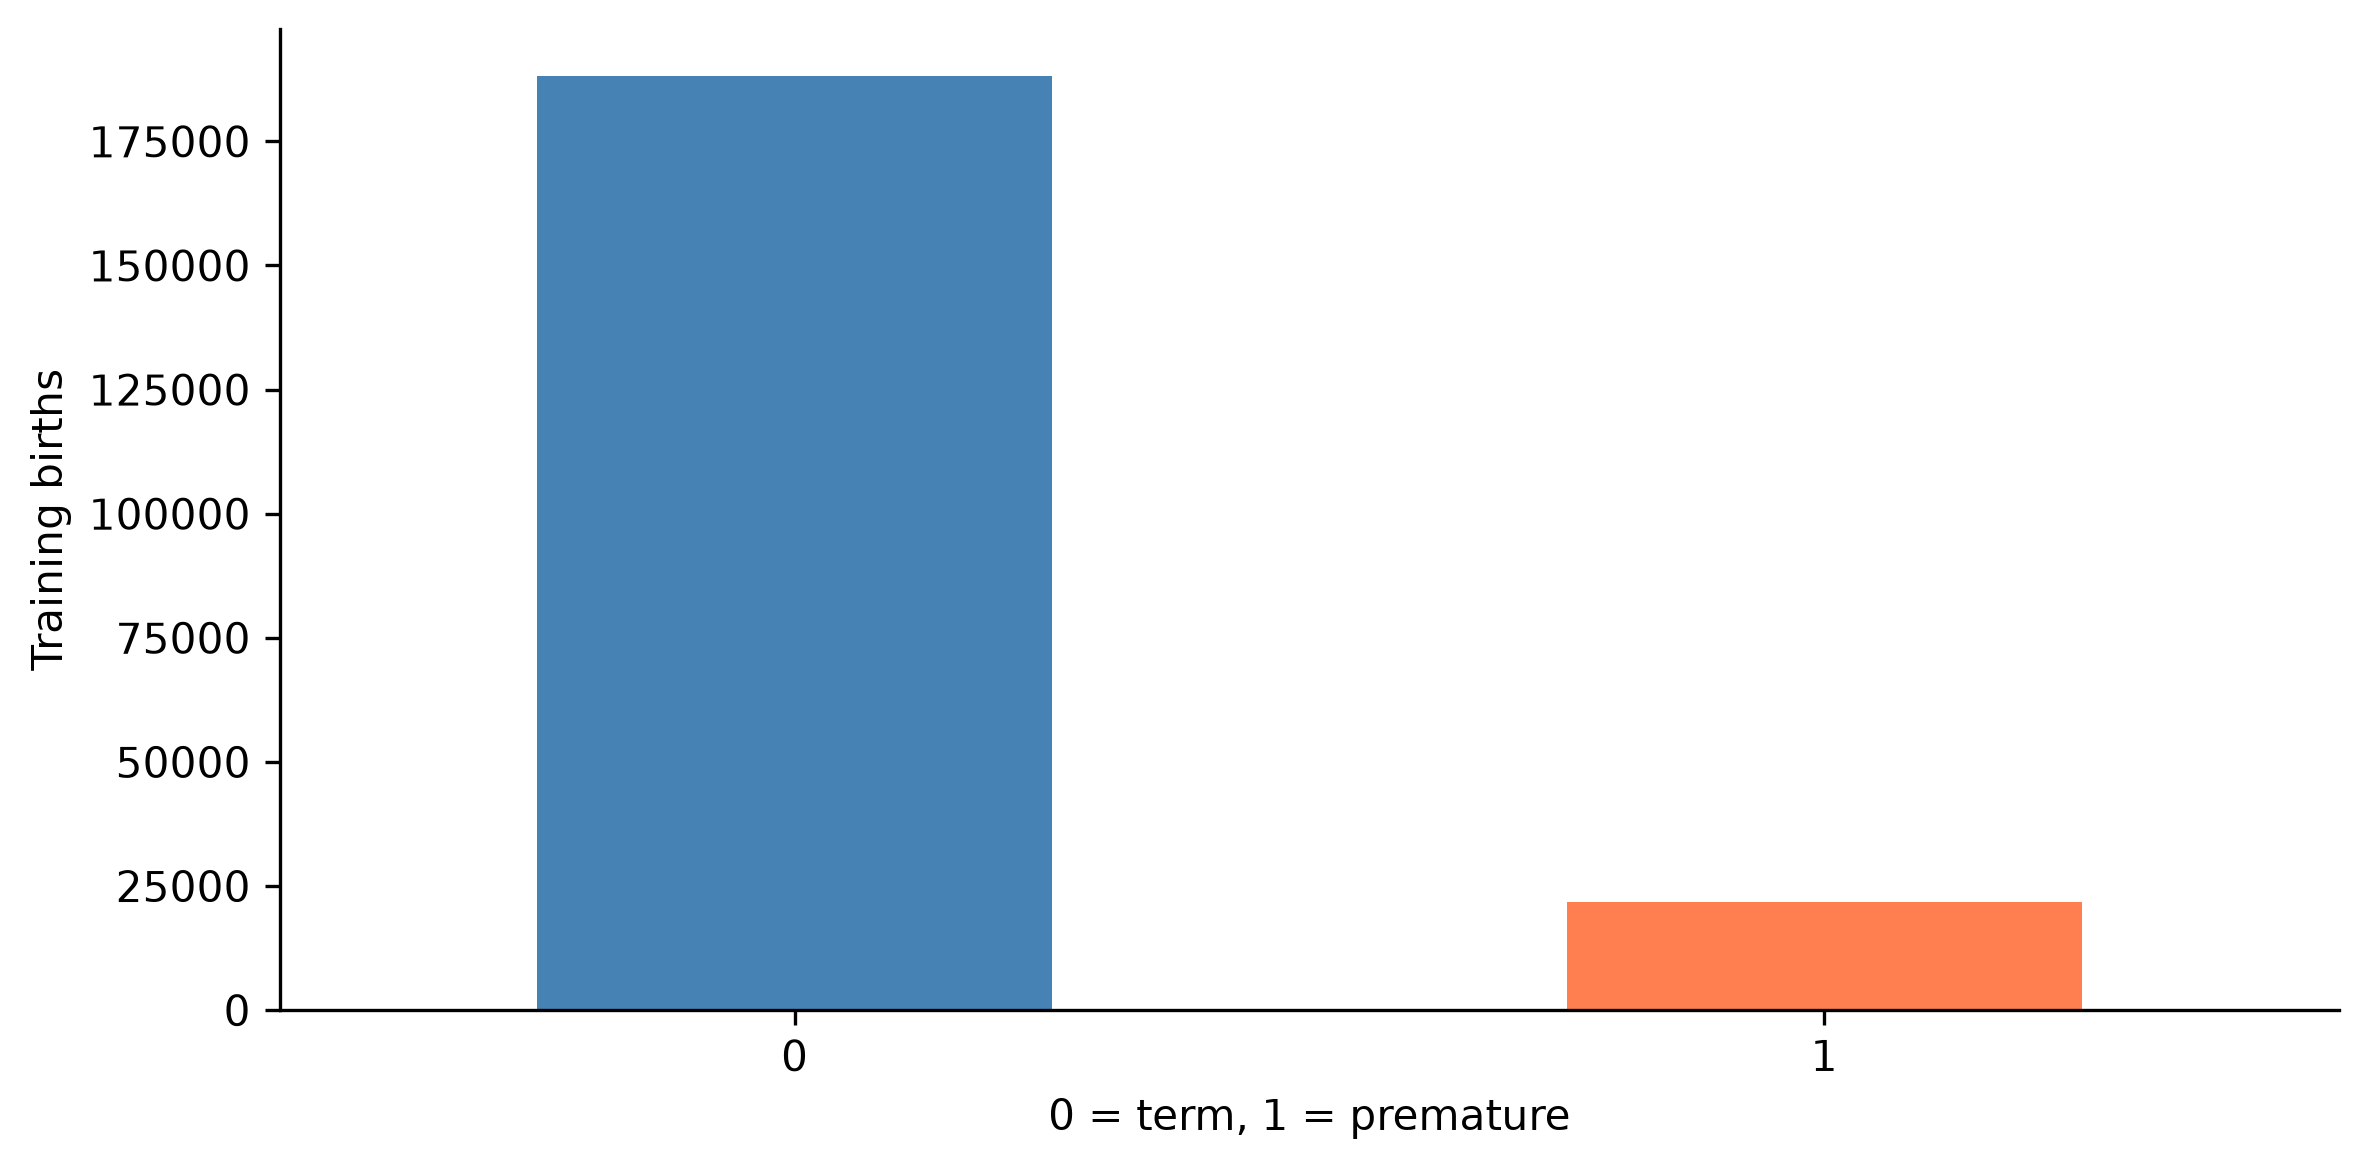

In [22]:
class_counts = y_train.value_counts().sort_index().rename_axis('preterm_birth').to_frame('rows')
class_counts['fraction'] = class_counts.rows / len(y_train)
display(class_counts)
class_counts.rows.plot.bar(rot=0,color=['steelblue','coral'])
plt.xlabel('0 = term, 1 = premature'); plt.ylabel('Training births')
save_figure('training_class_balance')

## Training EDA — rates by clinically relevant groups

Associations use training data; payment category is reporting-only.

,training_births,preterm_rate
maternal_age_group,,
20–24,35218,0.098501
25–29,57437,0.096488
30–34,64403,0.100135
35–39,35973,0.117004
40+,8838,0.149355
<20,8131,0.104907


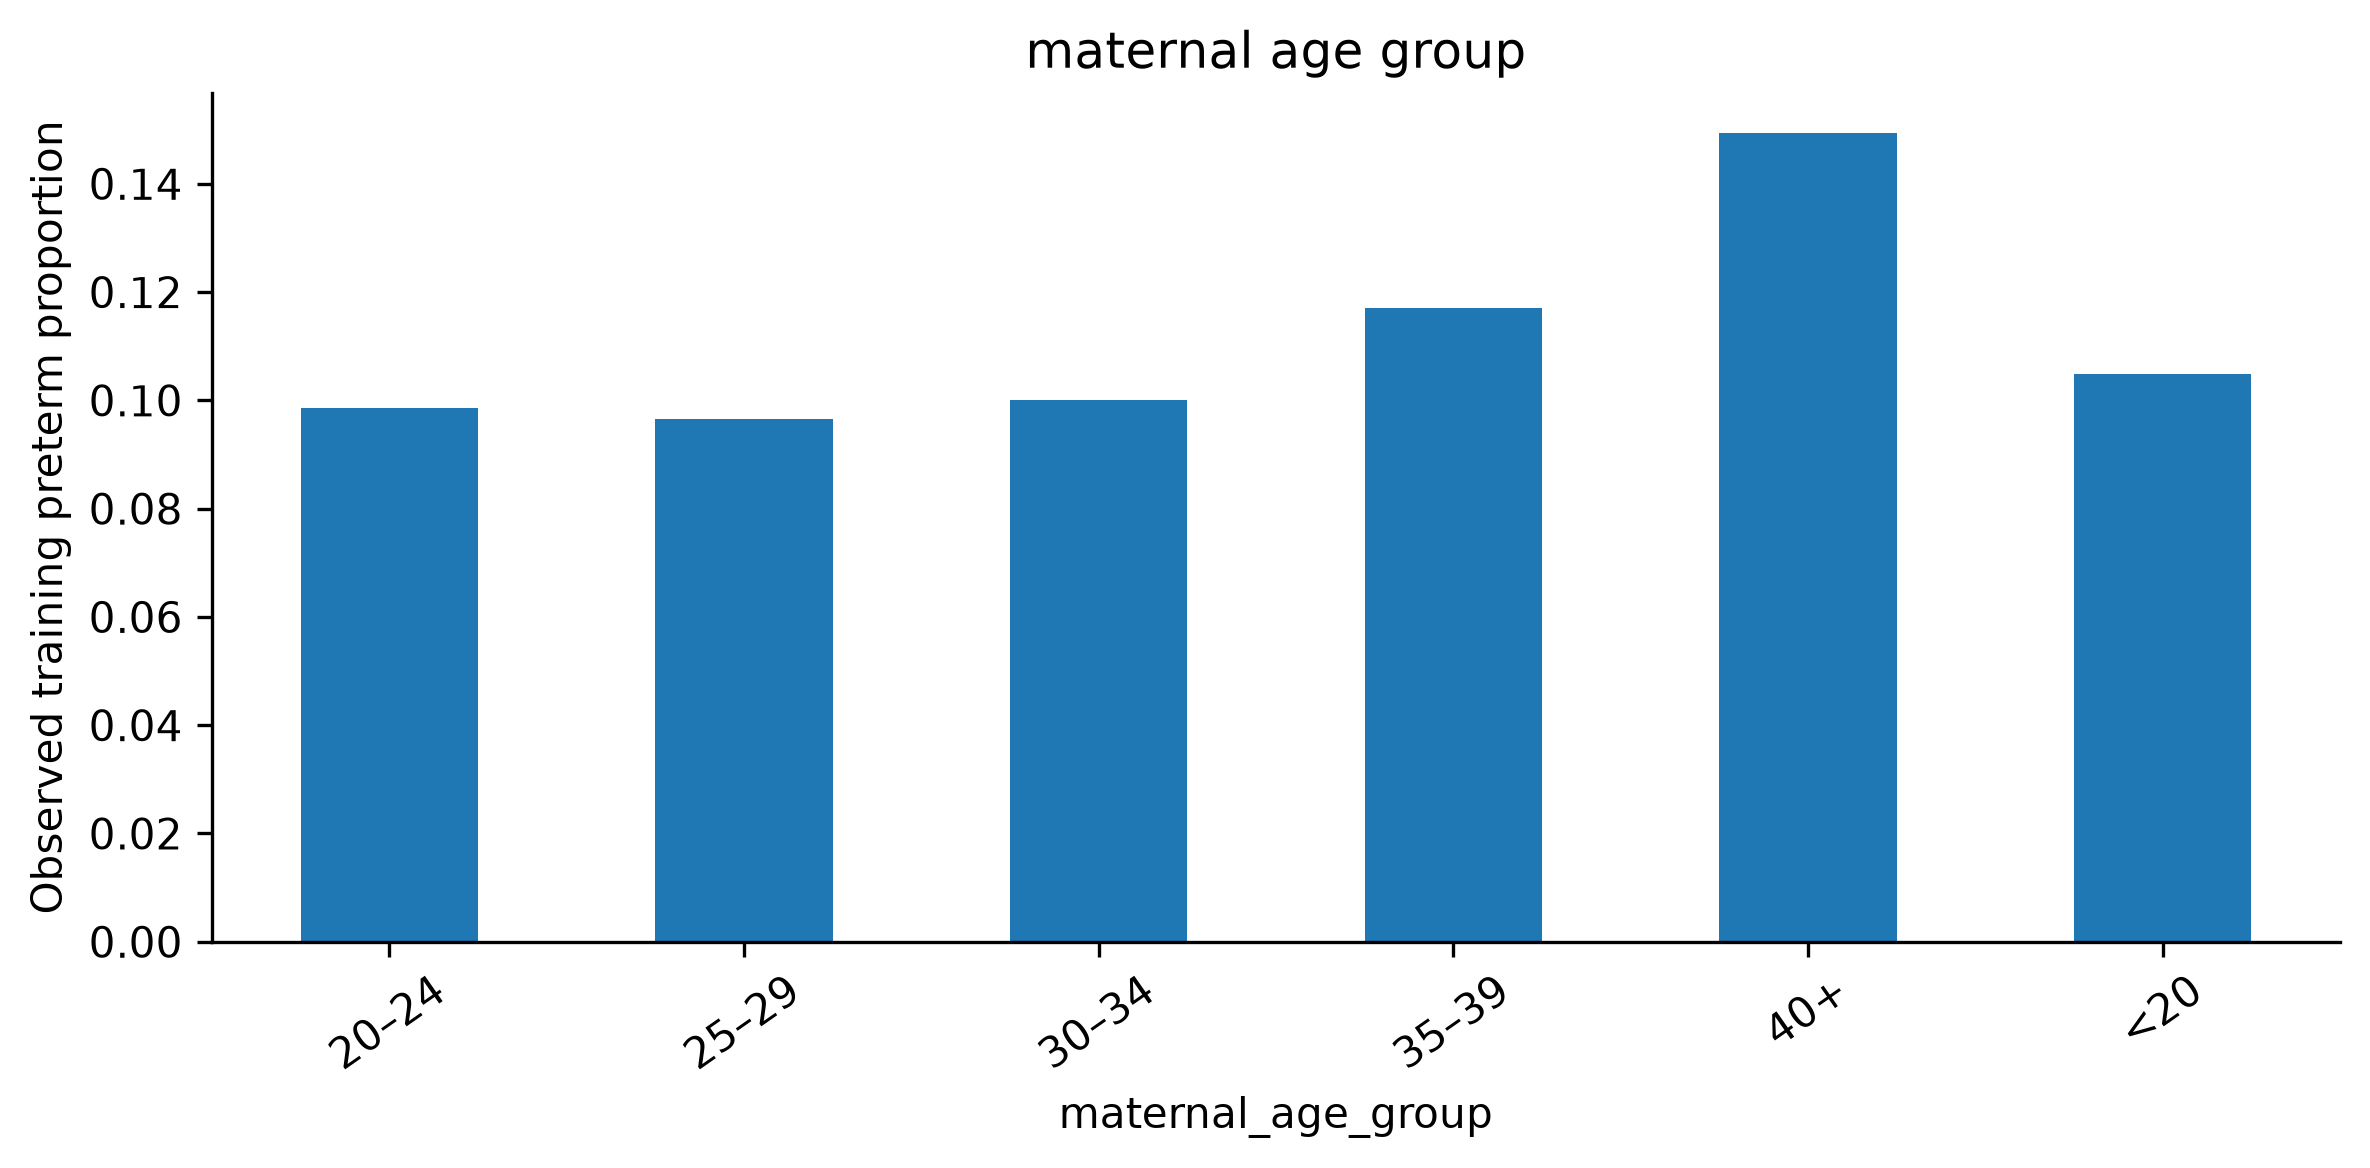

,training_births,preterm_rate
prepregnancy_bmi_category,,
__MISSING__,5553,0.138124
normal,75945,0.089499
obesity_I,35134,0.111288
obesity_II,17797,0.125077
obesity_III,12920,0.152322
overweight,57263,0.096589
underweight,5388,0.119339


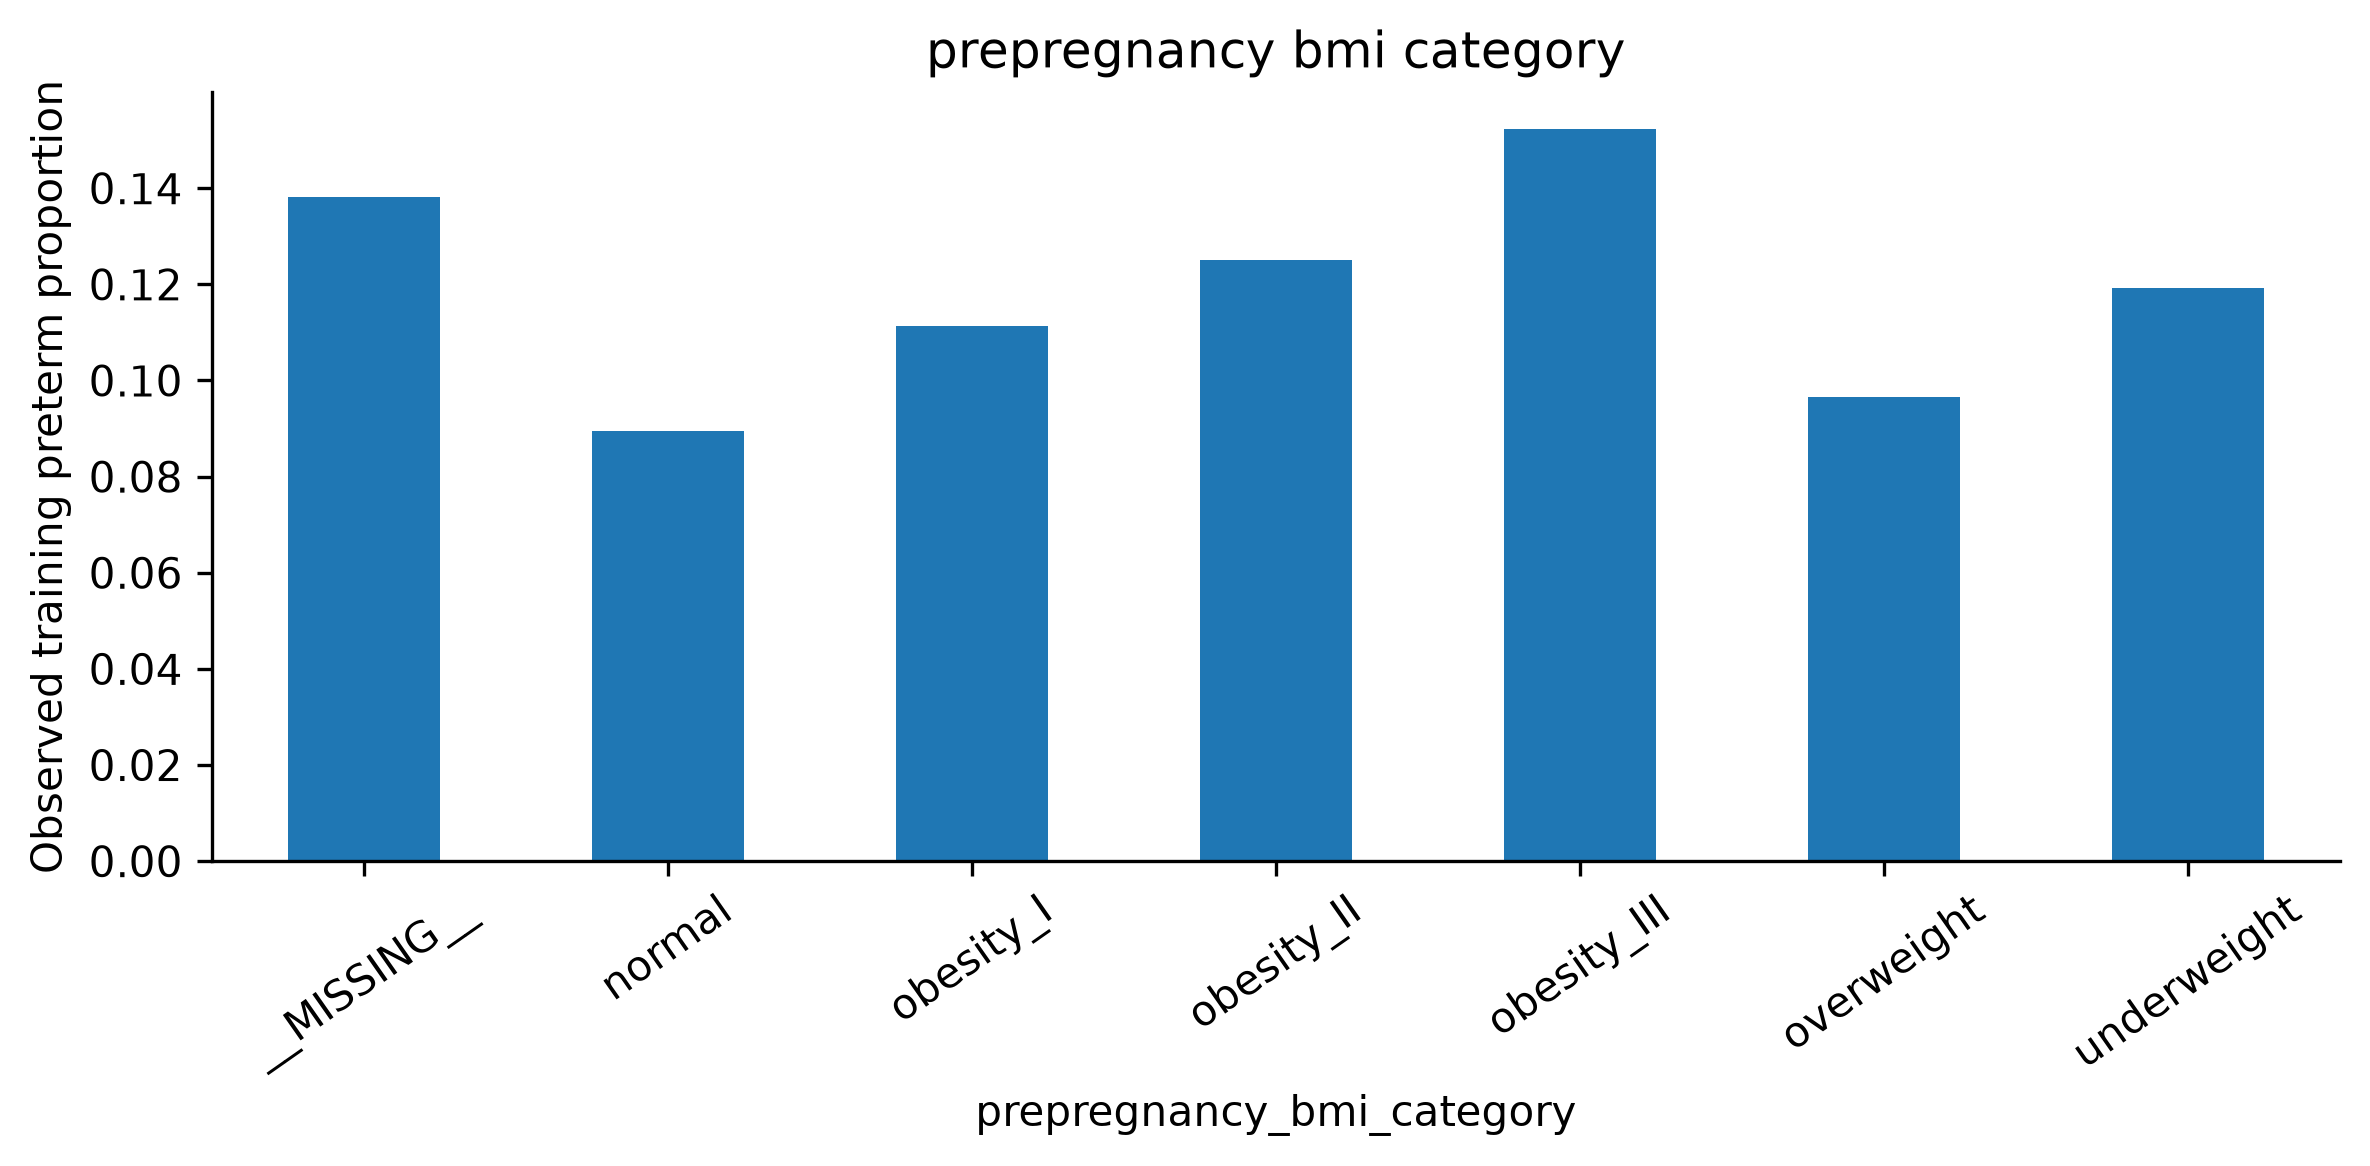

,training_births,preterm_rate
previous_preterm_birth,,
N,200791,0.096090
Y,8391,0.292695
__MISSING__,818,0.112469


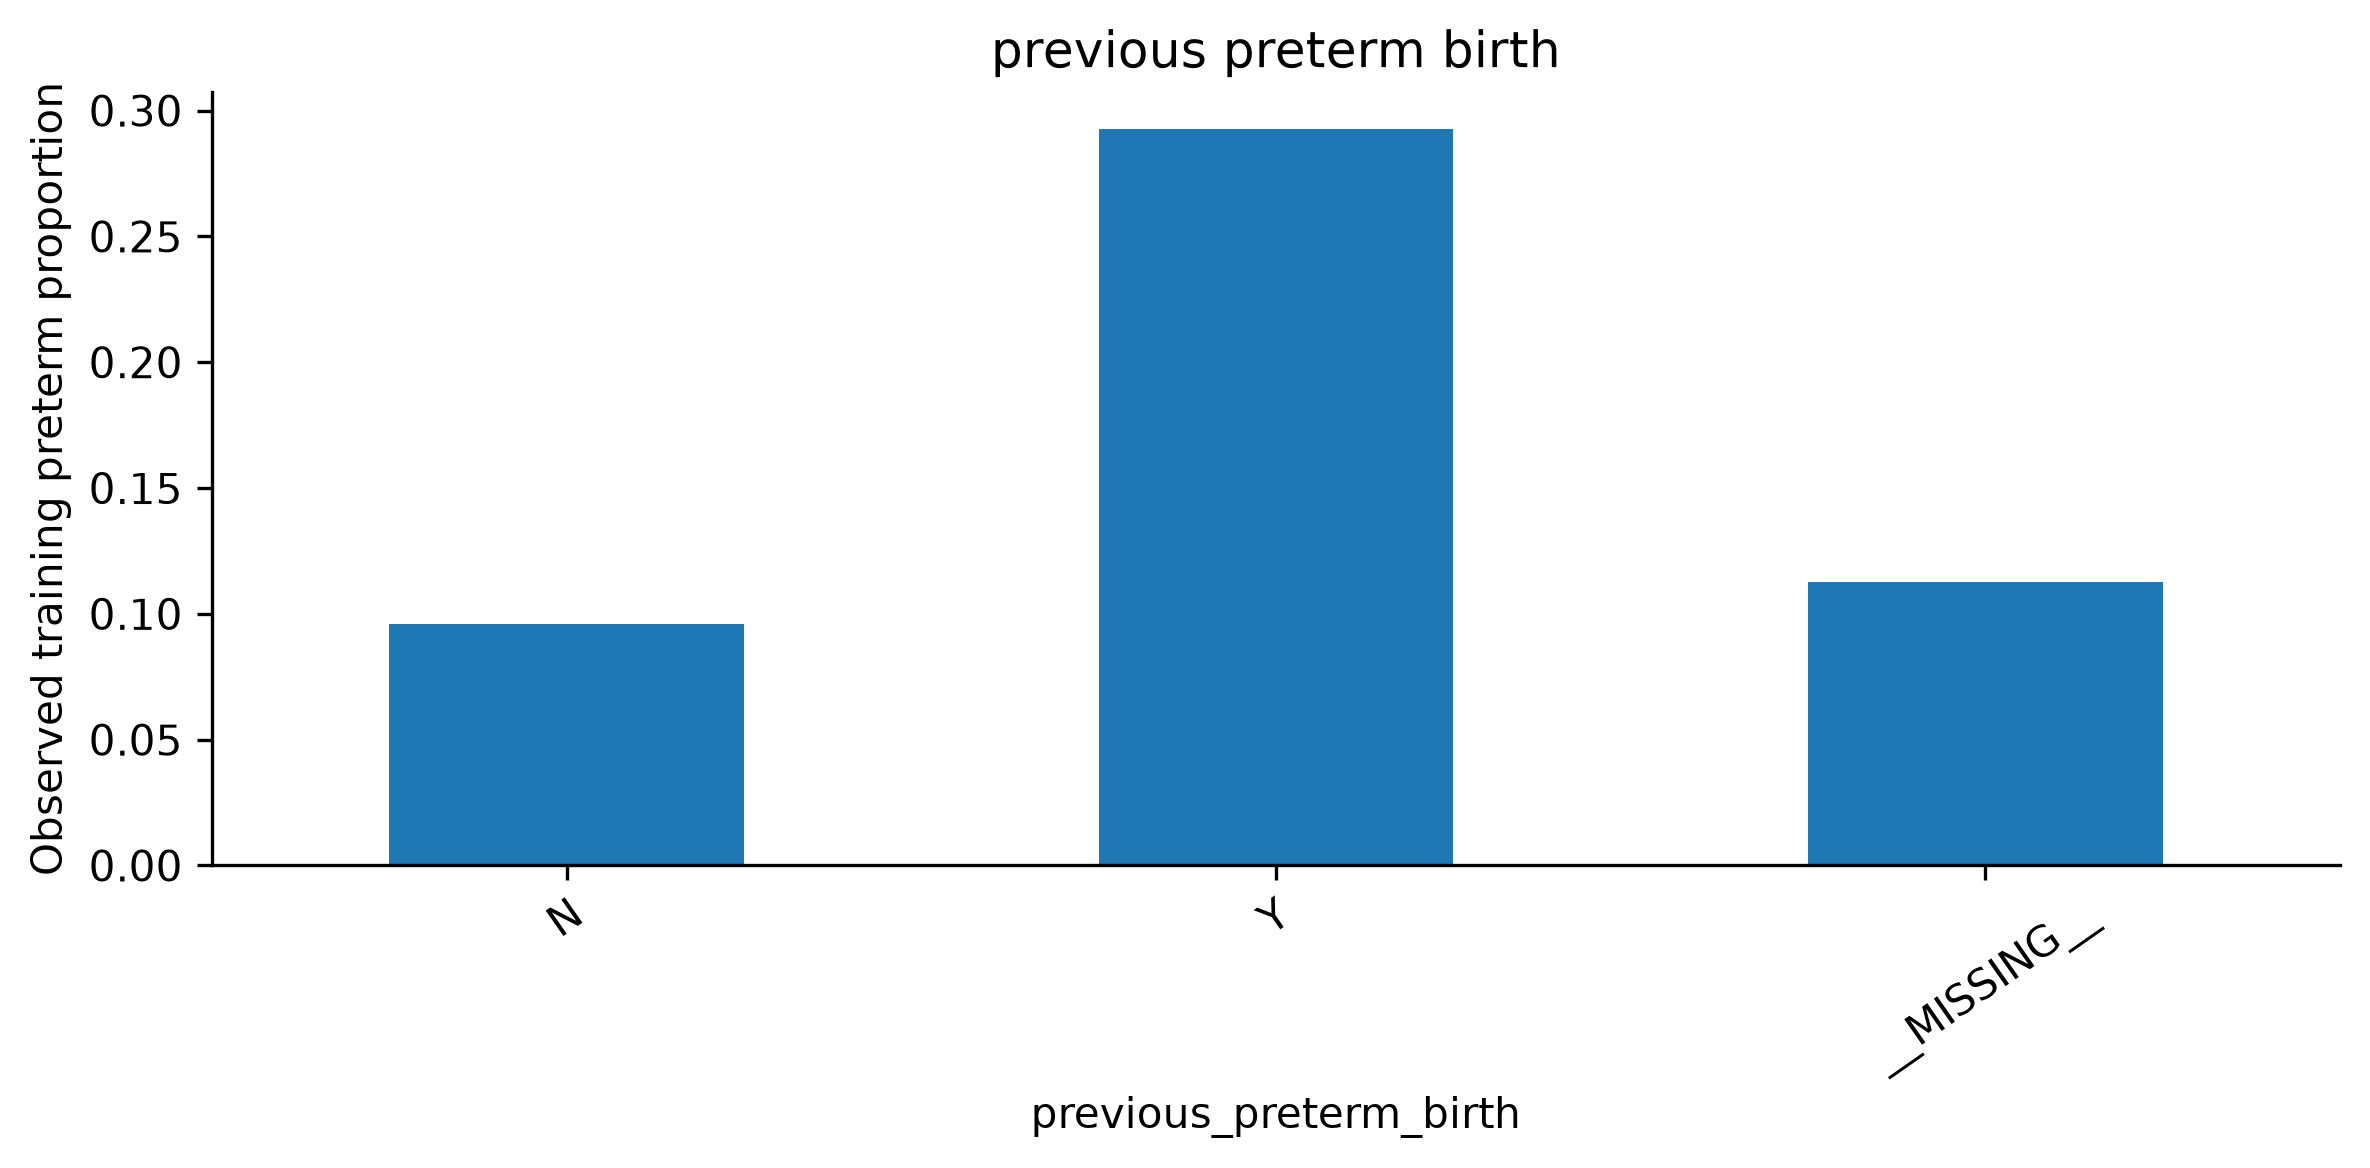

,training_births,preterm_rate
pregnancy_plurality,,
1.0,203568,0.088015
2.0,6286,0.601495
3.0,138,0.985507
4.0,8,1.000000


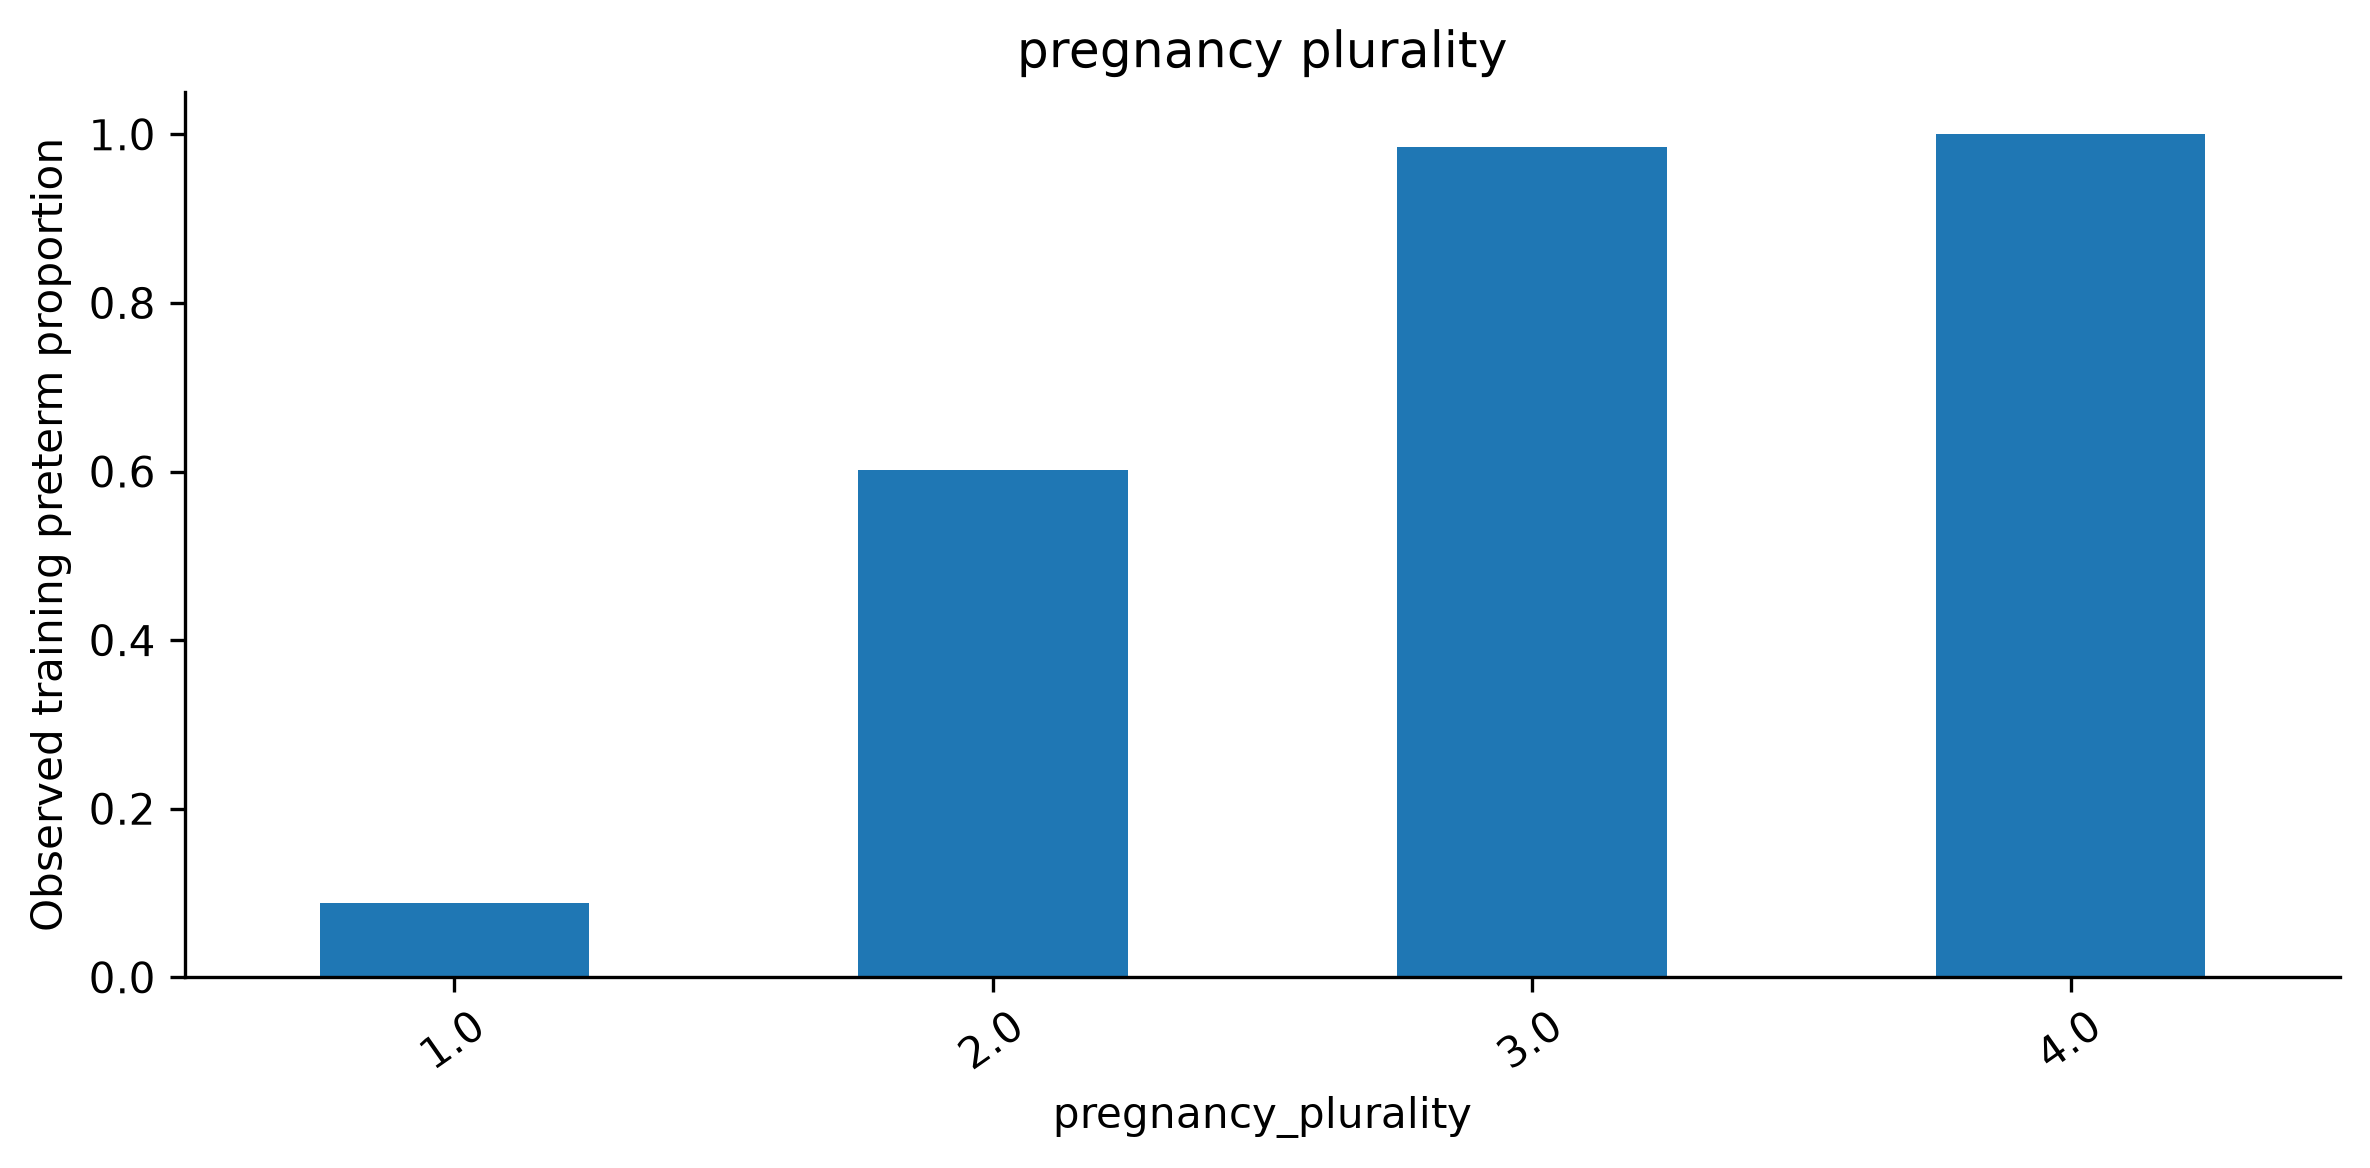

,training_births,preterm_rate
maternal_education,,
1.0,7010,0.100000
2.0,16473,0.120561
3.0,55889,0.113439
4.0,34301,0.111484
5.0,16810,0.107674
6.0,46399,0.086661
7.0,22166,0.091627
8.0,6663,0.087198
__MISSING__,4289,0.127769


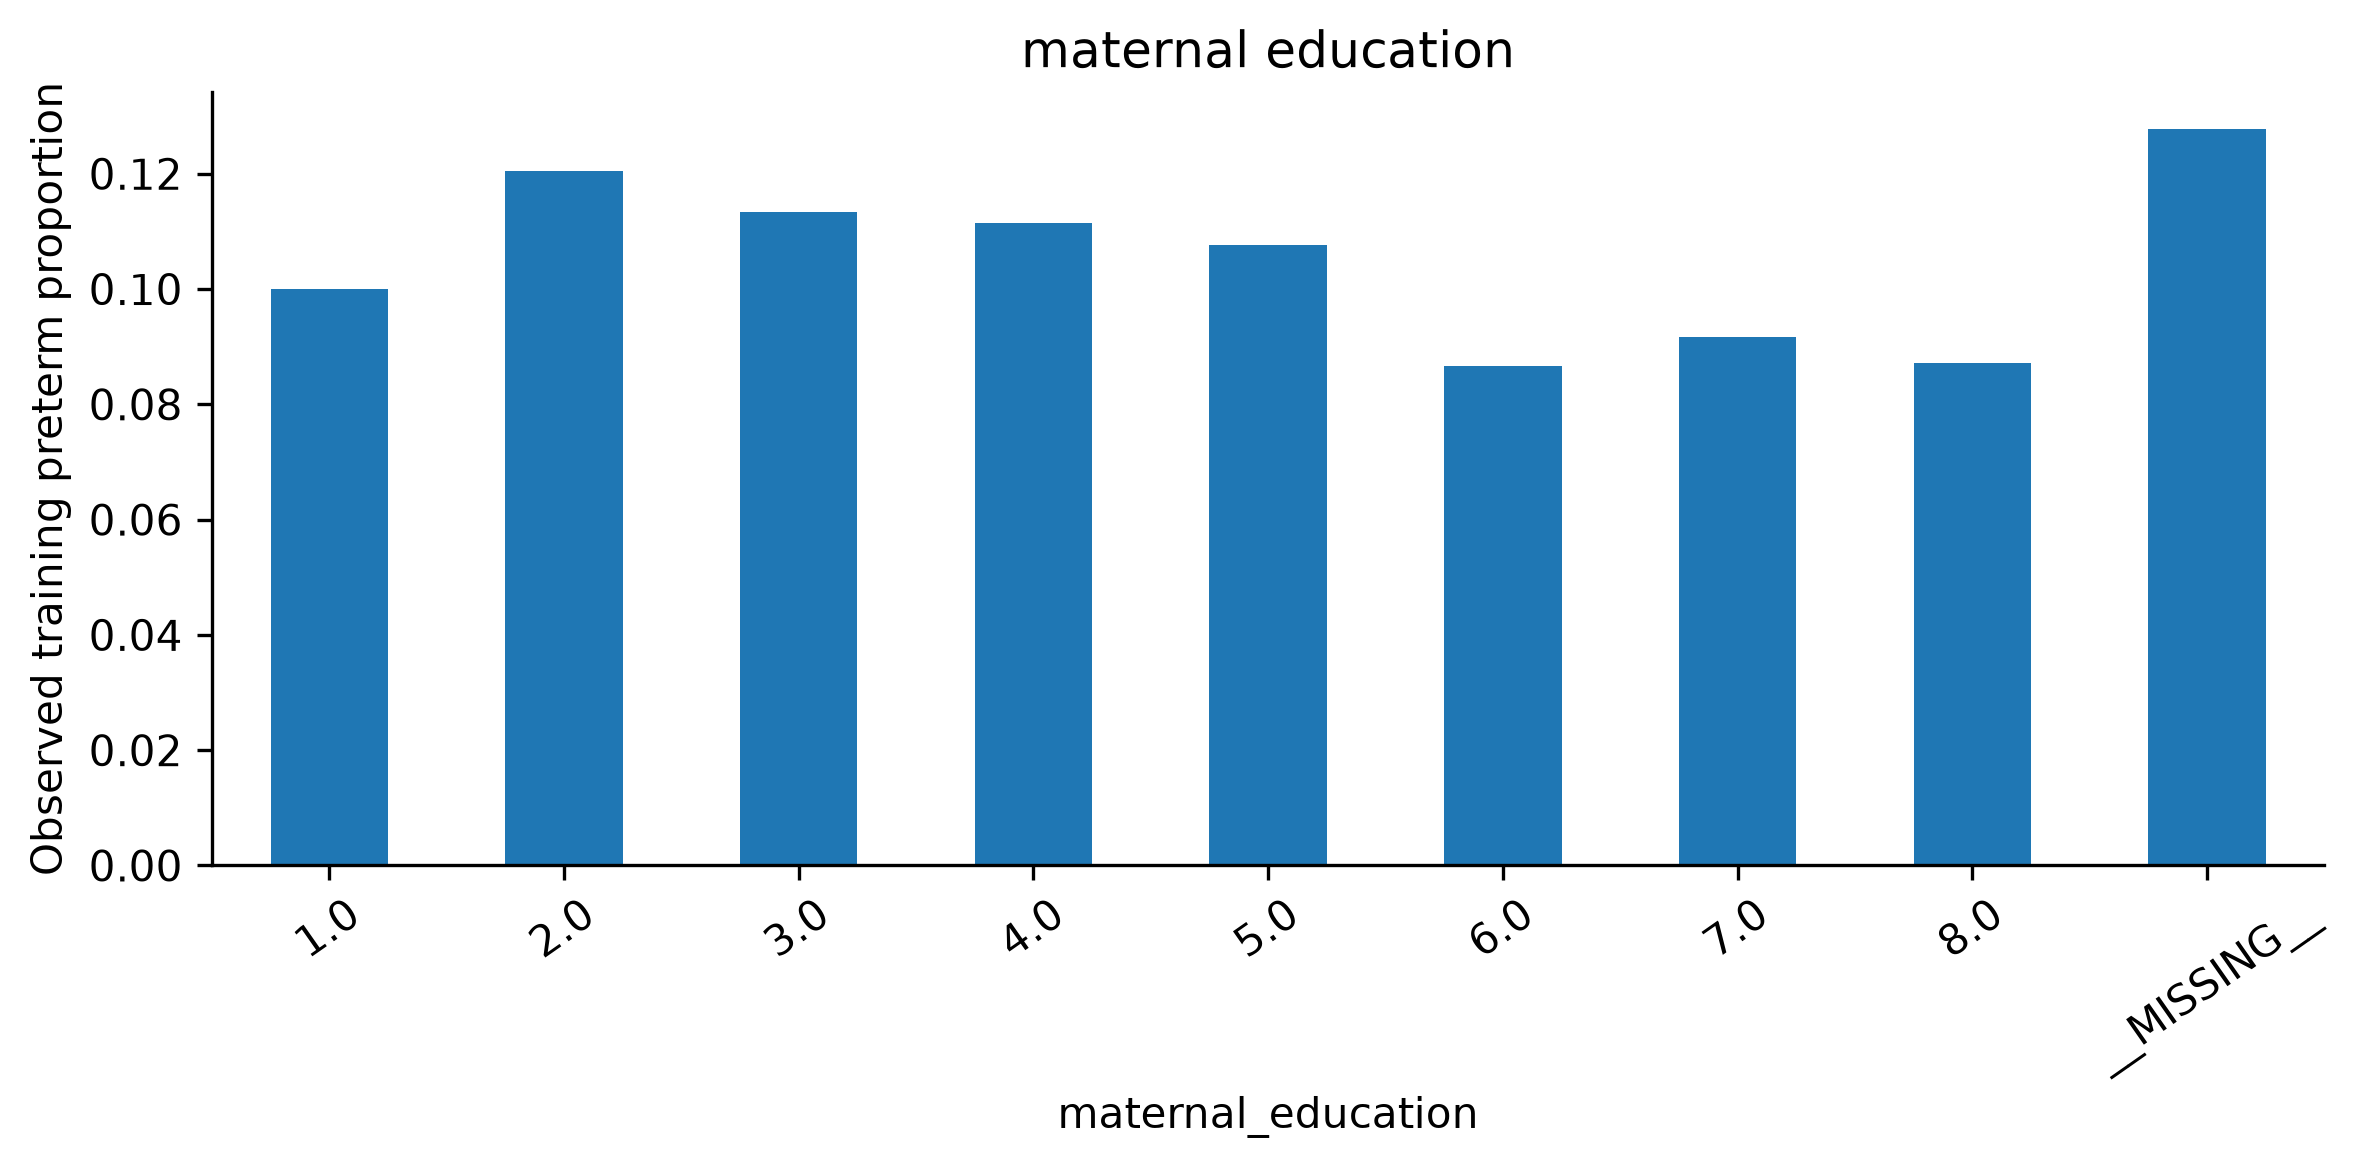

,training_births,preterm_rate
delivery_payment_category,,
1.0,83383,0.117614
2.0,107836,0.095840
3.0,9625,0.080104
4.0,7029,0.099872
NaN,2127,0.106723


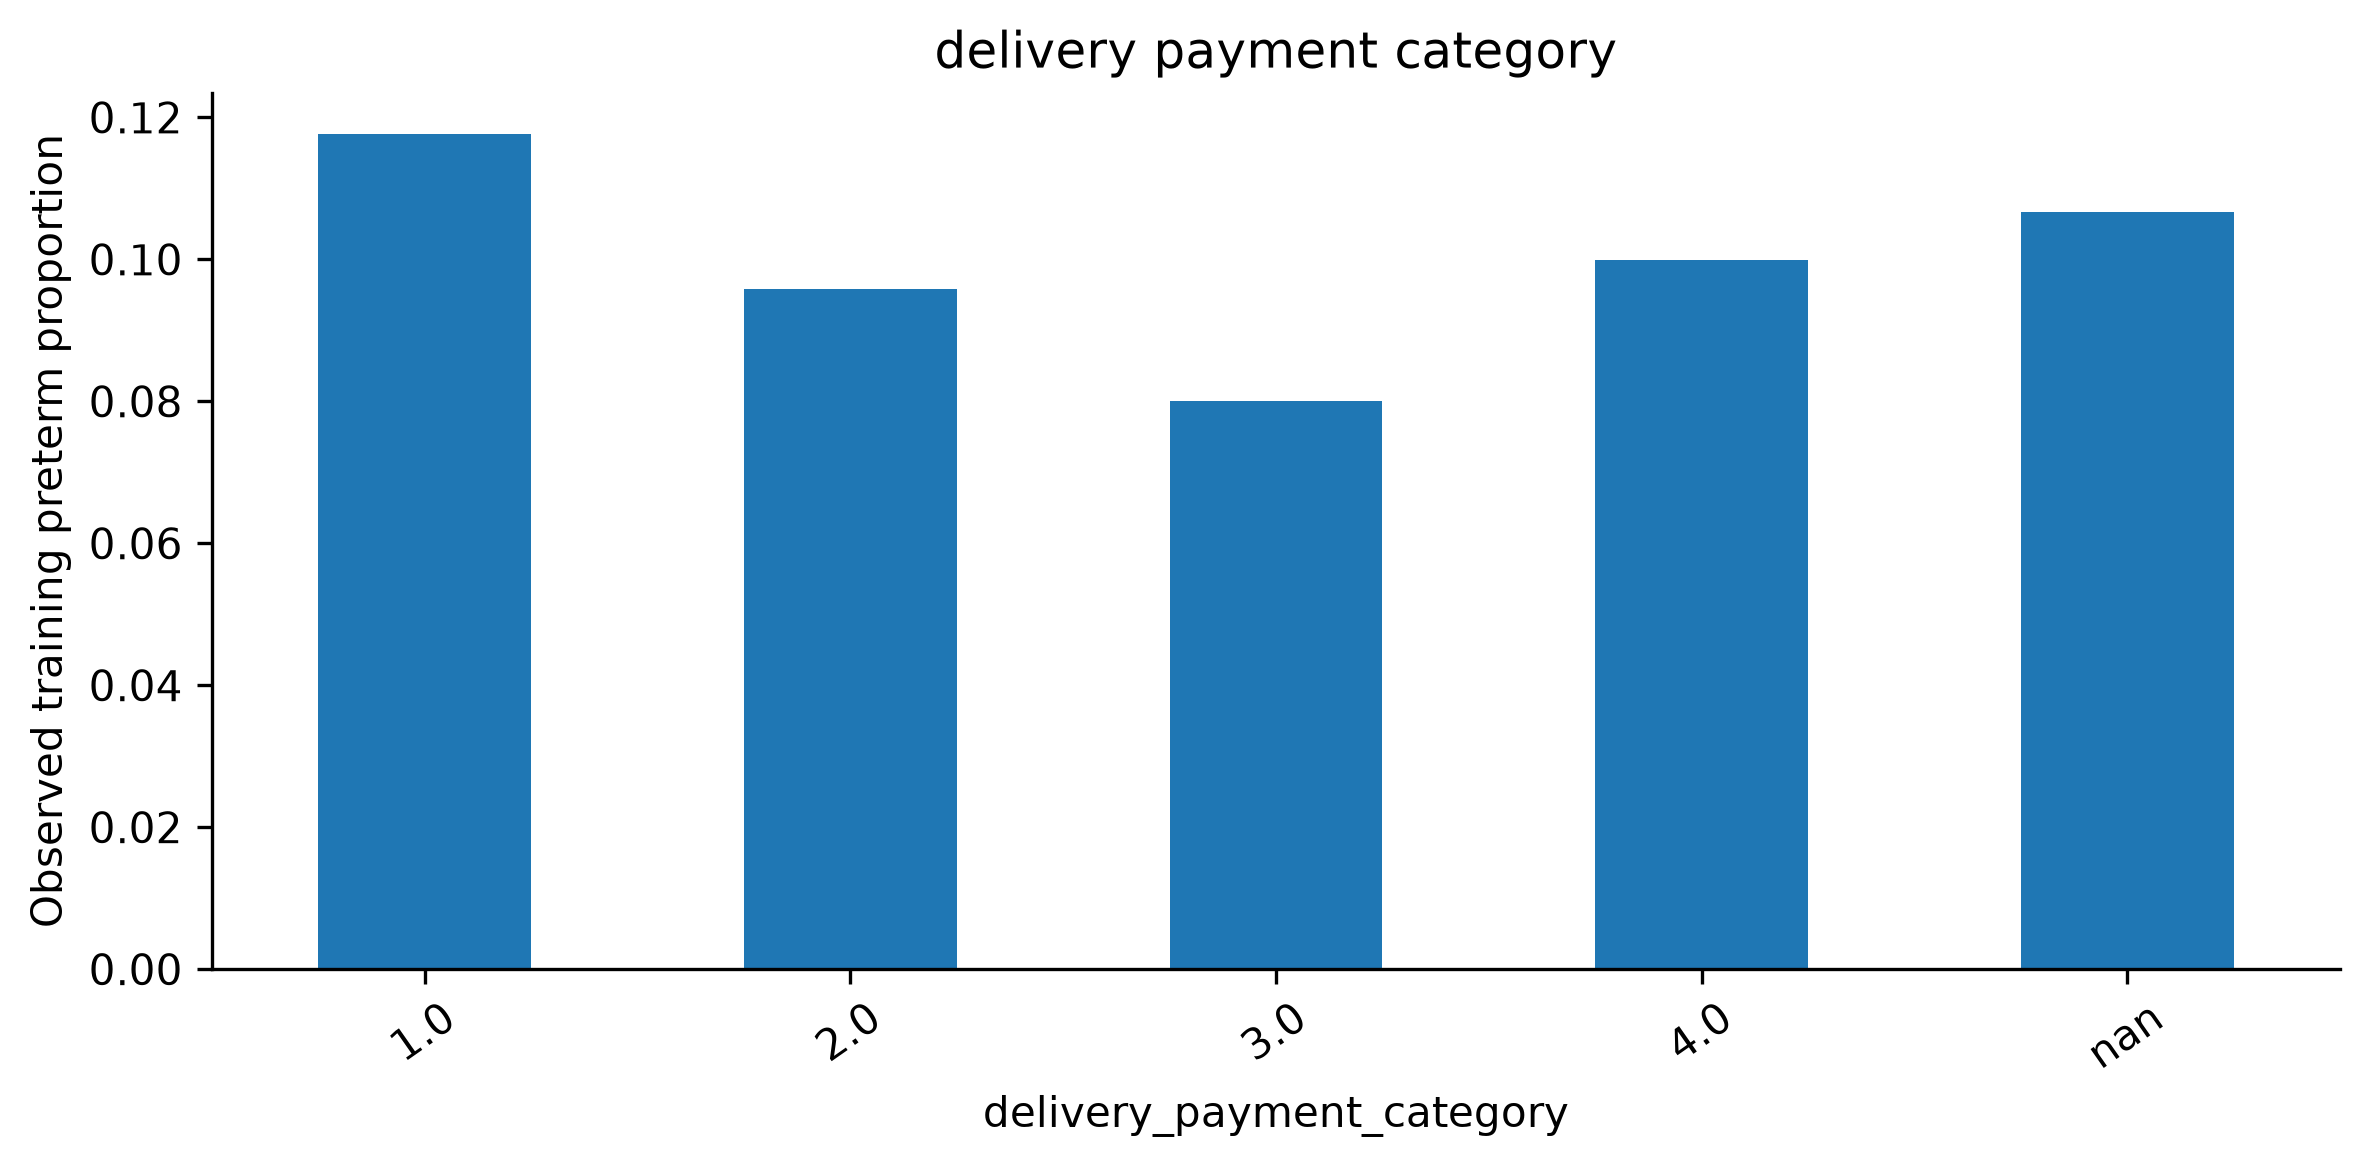

In [23]:
eda = X_train.assign(preterm_birth=y_train.to_numpy())
eda['delivery_payment_category'] = train.PAY_REC.to_numpy()
for field in ['maternal_age_group','prepregnancy_bmi_category','previous_preterm_birth',
              'pregnancy_plurality','maternal_education','delivery_payment_category']:
    rates = eda.groupby(field,dropna=False,observed=True).preterm_birth.agg(['size','mean'])
    rates.columns = ['training_births','preterm_rate']
    display(rates)
    rates.preterm_rate.plot.bar(rot=35)
    plt.ylabel('Observed training preterm proportion'); plt.title(field.replace('_',' '))
    save_figure('rate_'+field)

## Train/validation/test split

Use the existing stratified 70/15/15 split.

In [24]:
display(pd.read_csv(TABLES/'stage4_split_manifest.csv'))
assert not set(train.row_id) & set(validation.row_id)
assert len(train_ids)+len(validation_ids)+len(test_ids) == len(data)
cv = StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED)
tuning_ids = train_test_split(np.arange(len(y_train)),train_size=min(TUNING_ROWS,len(y_train)-1),
                             stratify=y_train,random_state=SEED)[0]
svm_ids = train_test_split(np.arange(len(y_train)),train_size=min(SVM_ROWS,len(y_train)-1),
                          stratify=y_train,random_state=SEED)[0]
print({'training_tuning_rows':len(tuning_ids),'svm_rows':len(svm_ids),
       'svm_positives':int(y_train.iloc[svm_ids].sum()),'folds':CV_FOLDS})

,split,rows,row_id_sha256
0,train,210000,a2122b17b7fa70c91b04d73fd281aa56e01c48a1867125...
1,validation,45000,e0d3e5c8a8bb717f9a4cbcda97f83846a3c11bcb5daabd...
2,test_locked,45000,de1fde0c051f6862e59ccd67afb98ea5897a10721f0e33...


{'training_tuning_rows': 60000, 'svm_rows': 6000, 'svm_positives': 624, 'folds': 3}


## Preprocessing — imputation, scaling and one-hot encoding

Fit numeric imputation, scaling and category encoding on training rows only.

In [25]:
def make_preprocessor(numeric=None, categorical=None, dense=True):
    numeric = numeric_features if numeric is None else numeric
    categorical = categorical_features if categorical is None else categorical
    numeric_pipeline = Pipeline([
        ('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scale',StandardScaler())])
    categorical_pipeline = Pipeline([
        ('impute',SimpleImputer(strategy='constant',fill_value='__MISSING__',keep_empty_features=True)),
        ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=not dense))])
    return ColumnTransformer([('numeric',numeric_pipeline,numeric),
                              ('categorical',categorical_pipeline,categorical)],sparse_threshold=0)

preprocessor = make_preprocessor()
preprocessor.fit(X_train)  # training only
training_probe = preprocessor.transform(X_train.head(5))
validation_probe = preprocessor.transform(X_validation.head(5))  # transform, never fit
assert np.isfinite(training_probe).all() and np.isfinite(validation_probe).all()
print('Transformed columns:',training_probe.shape[1])
display(preprocessor)
imputer = preprocessor.named_transformers_['numeric'].named_steps['impute']
display(pd.DataFrame({'feature':numeric_features,'training_median':imputer.statistics_}))
display(pd.read_csv(TABLES/'stage4_fit_provenance.json') if False else
        pd.Series(json.loads((TABLES/'stage4_fit_provenance.json').read_text())))

Transformed columns: 109


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

,feature,training_median
0,maternal_age_years,30.0
1,paternal_age_years,32.0
2,previous_births_now_living,1.0
3,previous_births_now_deceased,0.0
4,previous_other_pregnancy_terminations,0.0
5,daily_cigarettes_before_pregnancy,0.0
6,maternal_height_inches,64.0
7,prepregnancy_body_mass_index,26.6
8,prepregnancy_weight_pounds,155.0
9,previous_cesarean_count,0.0


fit_split                                                            train
fit_rows                                                            210000
validation_fit_rows                                                      0
test_fit_rows                                                            0
stateless_engineering                                                 True
numeric                  [MAGER, FAGECOMB, PRIORLIVE, PRIORDEAD, PRIORT...
categorical              [MRACEHISP, DMAR, MEDUC, LBO_REC, TBO_REC, RF_...
transformed_dimension                                                  109
missing_indicators       Numeric SimpleImputer(add_indicator=True); cat...
experiments              [Baseline versus engineered, With versus witho...
dtype: object

## Leakage sanity check

Investigate unexpected core ROC-AUC above 0.85 before continuing.

In [26]:
display(pd.read_csv(TABLES/'stage3_leakage_audit.csv'))
display(pd.Series(json.loads((TABLES/'stage3_sanity.json').read_text())))
display(pd.read_csv(TABLES/'stage3_shallow_tree_importance.csv'))
if RUN_TRAINING:
    shallow = Pipeline([('preprocessing',make_preprocessor()),
        ('model',DecisionTreeClassifier(max_depth=3,min_samples_leaf=200,random_state=SEED))])
    shallow.fit(X_train,y_train)
    shallow_auc = roc_auc_score(y_validation,shallow.predict_proba(X_validation)[:,1])
    print('Shallow-tree validation ROC-AUC:', shallow_auc)
    assert shallow_auc <= .85, 'Investigate leakage before continuing'

,field,input_role,decision,reason
0,DOB_YY,EXCLUDE_leakage,EXCLUDE,birth date outcome-dependent
1,DOB_MM,EXCLUDE_leakage,EXCLUDE,birth month shifts with gestation
2,DOB_TT,EXCLUDE_leakage,EXCLUDE,delivery time
3,DOB_WK,EXCLUDE_leakage,EXCLUDE,delivery weekday
4,BFACIL,EXCLUDE_leakage,EXCLUDE,place of delivery
...,...,...,...,...
214,NO_CONGEN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
215,ITRAN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
216,ILIVE,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
217,BFED,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...


development_rows                                                                255000
reserved_test_rows                                                               45000
sanity_roc_auc                                                                 0.63647
depth                                                                                3
auc_investigation_trigger                                                         0.85
implausibly_high_importance_flags                           [categorical__DPLURAL_1.0]
investigation                                                           No AUC trigger
short_interpregnancy_interval        Not safely derivable: ILP_R uses current birth...
limitations                          [Row-level data lack maternal/pregnancy identi...
importance_review                    DPLURAL has high shallow-tree importance; plur...
dtype: object

,feature,importance
0,categorical__DPLURAL_1.0,0.819258
1,categorical__RF_PPTERM_Y,0.127286
2,categorical__RF_PHYPE_Y,0.030201
3,categorical__DPLURAL_2.0,0.010475
4,categorical__RF_PPTERM_N,0.006720
...,...,...
104,categorical__bmi_category_obesity_I,0.000000
105,categorical__bmi_category_obesity_II,0.000000
106,categorical__bmi_category_obesity_III,0.000000
107,categorical__bmi_category_overweight,0.000000


**Interpretation:** Strong plurality/history signals need timing scrutiny; prospective usefulness is unproven.